In [1]:
from google.colab import drive
import os

drive.mount('/content/drive')
base = "/content/drive/MyDrive/UTokyo/Proteome"

Mounted at /content/drive


# 1 - Annotation merge

In [ ]:
# =====================================================================
# Secretome annotation merge — 7-strain cohort, SP+ and SP- separately
#   Sources : eggNOG (whole-proteome) + InterProScan + Foldseek rescue
#   Anchor  : {strain}/09_final SP_pos / SP_neg secretome FASTA IDs
#   Output  : {strain}_SP_pos_secretome_annotated_foldseek.tsv  (+ _neg)
#             ALL_secretome_annotation_summary.tsv
#   GO_final / Pfam_final = eggNOG ∪ InterPro ∪ Foldseek(rescue) union
# =====================================================================
import os, re, gc, glob
import numpy as np
import pandas as pd
from io import StringIO

try: BASE
except NameError: BASE = base

ANN      = os.path.join(BASE, "8_Annotation_results")
DATA_PRE = os.path.join(BASE, "Publication", "data_pre")
os.makedirs(DATA_PRE, exist_ok=True)

# --- VERIFY: where the 09_final secretomes live in the Drive tree ----
SECRETOME_ROOT = os.path.join(BASE, "Prediction_vs_Detection")

# ---- strain config (phylogenetic order) -----------------------------
STRAINS = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic", "Bmin"]
PREFIX  = {"Spil":"Spil","Snat":"Snat","Stri":"Stri","Slin":"Slin",
           "Snec":"Snec","Smic":"Smic_jgi","Bmin":"Bmin"}          # Smic -> Smic_jgi
SPECIES = {"Spil":"Symbiodinium pilosum","Snat":"Symbiodinium natans",
           "Stri":"Symbiodinium tridacnidorum","Slin":"Symbiodinium linucheae",
           "Snec":"Symbiodinium necroappetens","Smic":"Symbiodinium microadriaticum",
           "Bmin":"Breviolum minutum"}

# annotation file templates (Smic is the special case for all three)
EGGNOG_FILE   = lambda s: os.path.join(ANN, "Smic_jgi.emapper.annotations") if s=="Smic" \
                          else os.path.join(ANN, f"{s}_background_eggnog.emapper.annotations")
INTERPRO_FILE = lambda s: os.path.join(ANN, "Symmic_jgi_noStar.faa.tsv") if s=="Smic" \
                          else os.path.join(ANN, f"{s}_background_interproscan.tsv")
FOLDSEEK_FILE = lambda s: os.path.join(ANN, "Symmic_jgi_noStar_jgi_foldseek_hits.tsv") if s=="Smic" \
                          else os.path.join(ANN, f"{s}_pro_foldseek_hits.tsv")

# Foldseek rescue cutoffs  (VERIFY these match the MS-run thresholds)
FS_EVALUE_MAX, FS_QCOV_MIN, FS_TCOV_MIN = 1e-3, 0.50, 0.50

# ---- regex / ID normalisation ---------------------------------------
GO_RE   = re.compile(r"GO:\d{7}")
PF_RE   = re.compile(r"PF\d{5}")
BMIN_RE = re.compile(r"(symbB\.v1\.2\.\d{6}\.t\d+)")
AF_RE   = re.compile(r"AF-([A-Z0-9]+)-F\d+")
UP_RE   = re.compile(r"([A-NR-Z][0-9][A-Z0-9]{3}[0-9]|[OPQ][0-9][A-Z0-9]{3}[0-9])")

def clean_protein_id(pid, strain):
    if not isinstance(pid, str): return pid
    pid = pid.strip()
    if strain == "Smic": return pid.replace("_", "|", 3)      # jgi_..._.. -> jgi|...
    if strain == "Bmin":
        m = BMIN_RE.search(pid); return m.group(1) if m else pid.split("|")[0]
    return pid

def extract_af_accession(t):
    if not isinstance(t, str): return None
    m = AF_RE.search(t);  m2 = UP_RE.search(t)
    return m.group(1) if m else (m2.group(1) if m2 else None)

def collect_tokens(rgx, *cells):
    s = set()
    for c in cells:
        if isinstance(c, str) and c and c != "-": s.update(rgx.findall(c))
    return ",".join(sorted(s))

def read_fasta_ids(path, strain):
    ids = set()
    with open(path) as fh:
        for line in fh:
            if line.startswith(">"):
                ids.add(clean_protein_id(line[1:].strip().split()[0], strain))
    return ids

# ---- secretome FASTA resolver (template first, recursive fallback) --
_REC_CACHE = {}
def _recursive_index(pattern):
    if pattern not in _REC_CACHE:
        hits = glob.glob(os.path.join(BASE, "**", pattern), recursive=True)
        _REC_CACHE[pattern] = {os.path.basename(h): h for h in hits}
    return _REC_CACHE[pattern]
def resolve_secretome(prefix, cls):                # cls in {"pos","neg"}
    pat = f"*_SP_{cls}_secretome_final.faa"
    direct = glob.glob(os.path.join(SECRETOME_ROOT, prefix, "09_final", pat))
    if direct: return direct[0]
    idx = _recursive_index(f"*_SP_{cls}_secretome_final.faa")
    cand = [p for b, p in idx.items() if b.startswith(prefix)]
    return cand[0] if cand else None

# ---- loaders --------------------------------------------------------
def load_eggnog(strain):
    path = EGGNOG_FILE(strain)
    if not os.path.exists(path):
        print(f"    [WARN] eggNOG missing: {path}")
        return pd.DataFrame(columns=["protein_id"])
    with open(path) as fh: lines = [l for l in fh if not l.startswith("##")]
    egg = pd.read_csv(StringIO("".join(lines)), sep="\t", dtype=str)
    egg = egg.rename(columns={"#query":"query"})
    keep = {"query":"protein_id","eggNOG_OGs":"eggNOG_OGs","COG_category":"COG_category",
            "Description":"Description","Preferred_name":"Preferred_name",
            "GOs":"eggnog_GO","KEGG_ko":"KEGG_ko","PFAMs":"eggnog_Pfam"}
    egg = egg[[c for c in keep if c in egg.columns]].rename(columns=keep)
    egg["protein_id"] = egg["protein_id"].map(lambda x: clean_protein_id(x, strain))
    for c in ("eggnog_GO","eggnog_Pfam","eggNOG_OGs"):
        if c in egg: egg[c] = egg[c].replace("-", np.nan)
    return egg.drop_duplicates("protein_id")

IPR_COLS = ["acc","md5","len","analysis","sig_acc","sig_desc","start","stop",
            "score","status","date","ipr_acc","ipr_desc","go","pathways"]
def load_interpro_raw(strain):
    path = INTERPRO_FILE(strain)
    if not os.path.exists(path):
        print(f"    [WARN] InterPro missing: {path}")
        return pd.DataFrame(columns=IPR_COLS)
    rows = []
    with open(path) as fh:
        for line in fh:
            line = line.rstrip("\n")
            if not line: continue
            p = line.split("\t"); p += [""]*(15-len(p)); rows.append(p[:15])
    ip = pd.DataFrame(rows, columns=IPR_COLS)
    ip["acc"] = ip["acc"].map(lambda x: clean_protein_id(x, strain))
    return ip

def aggregate_interpro(ip_raw, id_set):
    if ip_raw.empty: return pd.DataFrame(columns=["protein_id"])
    sub = ip_raw[ip_raw["acc"].isin(id_set)]
    if sub.empty: return pd.DataFrame(columns=["protein_id"])
    def agg(g):
        ipr  = sorted({v for v in g["ipr_acc"]  if v and v != "-"})
        desc = sorted({v for v in g["ipr_desc"] if v and v != "-"})
        go   = sorted(set(GO_RE.findall(" ".join(g["go"].astype(str)))))
        pf   = sorted({a for a, an in zip(g["sig_acc"], g["analysis"])
                       if an == "Pfam" and isinstance(a, str) and a.startswith("PF")})
        return pd.Series({"interpro_acc":";".join(ipr), "interpro_desc":";".join(desc),
                          "interpro_GO":",".join(go), "interpro_Pfam":",".join(pf)})
    out = (sub.groupby("acc", sort=False)[["ipr_acc","ipr_desc","go","sig_acc","analysis"]]
              .apply(agg).reset_index())
    return out.rename(columns={"acc":"protein_id"})

FS7 = ["query","target","evalue","pident","alnlen","qcov","tcov"]
def load_foldseek(strain):
    path = FOLDSEEK_FILE(strain)
    if not os.path.exists(path):
        print(f"    [WARN] Foldseek missing: {path}")
        return pd.DataFrame(columns=["protein_id","target"])
    with open(path) as fh: ncol = len(fh.readline().rstrip("\n").split("\t"))
    cols = FS7 + ["tmscore"] if ncol >= 8 else FS7
    fs = pd.read_csv(path, sep="\t", header=None, names=cols[:ncol], dtype=str)
    for c in ("evalue","pident","alnlen","qcov","tcov"):
        if c in fs: fs[c] = pd.to_numeric(fs[c], errors="coerce")
    fs["query"] = fs["query"].map(lambda x: clean_protein_id(x, strain))
    fs = fs.sort_values("evalue").drop_duplicates("query", keep="first")
    return fs.rename(columns={"query":"protein_id"})

def pass_rescue_cutoff(sub):
    return ((sub["evalue"] <= FS_EVALUE_MAX) &
            (sub["qcov"].fillna(0) >= FS_QCOV_MIN) &
            (sub["tcov"].fillna(0) >= FS_TCOV_MIN))

# ---- Swiss-Prot GO/Pfam map (for rescue transfer) -------------------
def _load_sprot_map():
    cand = [os.path.join(ANN,      "uniprot_sprot_annotation_map.tsv"),
            os.path.join(DATA_PRE, "uniprot_sprot_annotation_map.tsv")]
    path = next((p for p in cand if os.path.exists(p)), None)
    if path is None:
        print("[WARN] uniprot_sprot_annotation_map.tsv not found — Foldseek hits "
              "will be flagged but GO/Pfam not transferred.")
        return None
    raw = pd.read_csv(path, sep="\t", dtype=str)
    if "foldseek_uniprot_acc" in raw.columns:                     # already normalized
        m = raw
    else:                                                         # raw UniProt export
        ren = {"Gene Ontology IDs":"foldseek_GO", "Pfam":"foldseek_Pfam",
               "Protein names":"foldseek_protein_name", "Gene Names":"foldseek_gene_name"}
        need = ["foldseek_GO","foldseek_Pfam","foldseek_protein_name","foldseek_gene_name"]
        frames = []
        for keycol in ("From", "Entry"):                          # match on either accession
            if keycol in raw.columns:
                sub = raw.rename(columns=ren).copy()
                sub["foldseek_uniprot_acc"] = raw[keycol]
                for c in need:
                    if c not in sub.columns: sub[c] = np.nan
                frames.append(sub[["foldseek_uniprot_acc"] + need])
        if not frames:
            print(f"[WARN] map at {path} lacks 'foldseek_uniprot_acc' and 'From'/'Entry'; "
                  f"columns = {list(raw.columns)} — GO/Pfam not transferred.")
            return None
        m = (pd.concat(frames, ignore_index=True)
               .dropna(subset=["foldseek_uniprot_acc"])
               .drop_duplicates("foldseek_uniprot_acc"))
    print(f"Swiss-Prot map: {len(m):,} accessions "
          f"({m['foldseek_GO'].notna().sum()} with GO) | source: {os.path.basename(path)}")
    return m

SPROT = _load_sprot_map()

# ---- per (strain, class) build --------------------------------------
def build_class_table(strain, cls, ids, egg, ipr_raw, fs):
    df = pd.DataFrame({"protein_id": sorted(ids)})
    df["strain"], df["sp_class"], df["species"] = strain, cls, SPECIES[strain]

    df = df.merge(egg, on="protein_id", how="left")
    df["has_eggnog"] = df.get("eggNOG_OGs", pd.Series(index=df.index)).notna()

    ipr = aggregate_interpro(ipr_raw, set(ids))
    df = df.merge(ipr, on="protein_id", how="left")
    df["has_interpro"] = (df.get("interpro_acc","").fillna("").ne("") |
                          df.get("interpro_Pfam","").fillna("").ne(""))

    df = df.merge(fs, on="protein_id", how="left")
    df["has_foldseek"] = df["target"].notna()

    df["is_fs_only_raw"] = df["has_foldseek"] & ~df["has_eggnog"] & ~df["has_interpro"]
    df["passes_rescue"]  = False
    m = df["is_fs_only_raw"]
    if m.any(): df.loc[m, "passes_rescue"] = pass_rescue_cutoff(df.loc[m]).values
    df["is_fs_rescue"] = df["is_fs_only_raw"] & df["passes_rescue"]

    df["foldseek_uniprot_acc"] = df["target"].map(extract_af_accession)
    if SPROT is not None:
        df = df.merge(SPROT, on="foldseek_uniprot_acc", how="left")
        for c in ["foldseek_GO","foldseek_Pfam","foldseek_protein_name","foldseek_gene_name"]:
            if c in df: df.loc[~df["is_fs_rescue"], c] = np.nan

    for c in ["eggnog_GO","interpro_GO","foldseek_GO",
              "eggnog_Pfam","interpro_Pfam","foldseek_Pfam"]:
        if c not in df.columns: df[c] = np.nan

    df["GO_final"]   = [collect_tokens(GO_RE, a,b,c)
                        for a,b,c in zip(df["eggnog_GO"],df["interpro_GO"],df["foldseek_GO"])]
    df["Pfam_final"] = [collect_tokens(PF_RE, a,b,c)
                        for a,b,c in zip(df["eggnog_Pfam"],df["interpro_Pfam"],df["foldseek_Pfam"])]
    df["annotation_status"] = np.select(
        [df["has_eggnog"] | df["has_interpro"], df["is_fs_rescue"]],
        ["homology","foldseek_rescue"], default="unannotated")
    return df

OUT_COLS = ["protein_id","strain","species","sp_class","annotation_status",
            "has_eggnog","has_interpro","has_foldseek","is_fs_rescue",
            "Preferred_name","Description","COG_category","eggNOG_OGs","KEGG_ko",
            "interpro_acc","interpro_desc",
            "eggnog_GO","interpro_GO","foldseek_GO","GO_final",
            "eggnog_Pfam","interpro_Pfam","foldseek_Pfam","Pfam_final",
            "target","evalue","qcov","tcov","foldseek_protein_name"]

summary = []
for strain in STRAINS:
    prefix = PREFIX[strain]
    print(f"\n{'='*68}\n{strain}  ({SPECIES[strain]})\n{'='*68}")
    pos_faa, neg_faa = resolve_secretome(prefix,"pos"), resolve_secretome(prefix,"neg")
    ids_pos = read_fasta_ids(pos_faa, strain) if pos_faa else set()
    ids_neg = read_fasta_ids(neg_faa, strain) if neg_faa else set()
    print(f"  SP+ FASTA: {os.path.basename(pos_faa) if pos_faa else 'NOT FOUND'}  (n={len(ids_pos)})")
    print(f"  SP- FASTA: {os.path.basename(neg_faa) if neg_faa else 'NOT FOUND'}  (n={len(ids_neg)})")
    if not (ids_pos or ids_neg):
        print("  [SKIP] no secretome FASTA — set SECRETOME_ROOT correctly."); continue

    egg     = load_eggnog(strain)
    ipr_raw = load_interpro_raw(strain)
    fs      = load_foldseek(strain)

    for cls, ids in [("SP_pos", ids_pos), ("SP_neg", ids_neg)]:
        if not ids: continue
        tbl = build_class_table(strain, cls, ids, egg, ipr_raw, fs)
        keep = [c for c in OUT_COLS if c in tbl.columns]
        out  = os.path.join(DATA_PRE, f"{strain}_{cls}_secretome_annotated_foldseek.tsv")
        tbl[keep].to_csv(out, sep="\t", index=False)

        n = len(tbl); ne = int(tbl["has_eggnog"].sum()); ni = int(tbl["has_interpro"].sum())
        nr = int(tbl["is_fs_rescue"].sum()); nfs = int(tbl["has_foldseek"].sum())
        neither = int((~tbl["has_eggnog"] & ~tbl["has_interpro"]).sum())
        ngo = int((tbl["GO_final"].str.len() > 0).sum())
        pct = 100*(tbl["annotation_status"] != "unannotated").mean()
        print(f"  [{cls}] n={n:>4} | eggNOG {ne} InterPro {ni} neither {neither} | "
              f"Foldseek-hit {nfs} rescued {nr} | GO_final≠∅ {ngo} | annotated {pct:4.1f}%")
        vc = tbl["annotation_status"].value_counts().to_dict()
        summary.append({"strain":strain,"sp_class":cls,"n":n,
                        "homology":vc.get("homology",0),
                        "foldseek_rescue":vc.get("foldseek_rescue",0),
                        "unannotated":vc.get("unannotated",0),
                        "pct_annotated":round(pct,1)})
    del egg, ipr_raw, fs; gc.collect()

sm = pd.DataFrame(summary)
sm.to_csv(os.path.join(DATA_PRE, "ALL_secretome_annotation_summary.tsv"), sep="\t", index=False)
print(f"\n{'='*68}\nSUMMARY\n{'='*68}"); print(sm.to_string(index=False))
print("\nDone.")

Swiss-Prot map: 5,575 accessions (5271 with GO) | source: uniprot_sprot_annotation_map.tsv

Spil  (Symbiodinium pilosum)
  SP+ FASTA: Spil_SP_pos_secretome_final.faa  (n=406)
  SP- FASTA: Spil_SP_neg_secretome_final.faa  (n=115)
  [SP_pos] n= 406 | eggNOG 186 InterPro 201 neither 183 | Foldseek-hit 399 rescued 29 | GO_final≠∅ 136 | annotated 62.1%
  [SP_neg] n= 115 | eggNOG 51 InterPro 47 neither 58 | Foldseek-hit 109 rescued 4 | GO_final≠∅ 30 | annotated 53.0%

Snat  (Symbiodinium natans)
  SP+ FASTA: Snat_SP_pos_secretome_final.faa  (n=983)
  SP- FASTA: Snat_SP_neg_secretome_final.faa  (n=274)
  [SP_pos] n= 983 | eggNOG 490 InterPro 500 neither 407 | Foldseek-hit 970 rescued 67 | GO_final≠∅ 341 | annotated 65.4%
  [SP_neg] n= 274 | eggNOG 131 InterPro 150 neither 106 | Foldseek-hit 266 rescued 22 | GO_final≠∅ 91 | annotated 69.3%

Stri  (Symbiodinium tridacnidorum)
  SP+ FASTA: Stri_SP_pos_secretome_final.faa  (n=1066)
  SP- FASTA: Stri_SP_neg_secretome_final.faa  (n=277)
  [SP_pos] 

# 2 - Annotation coverage

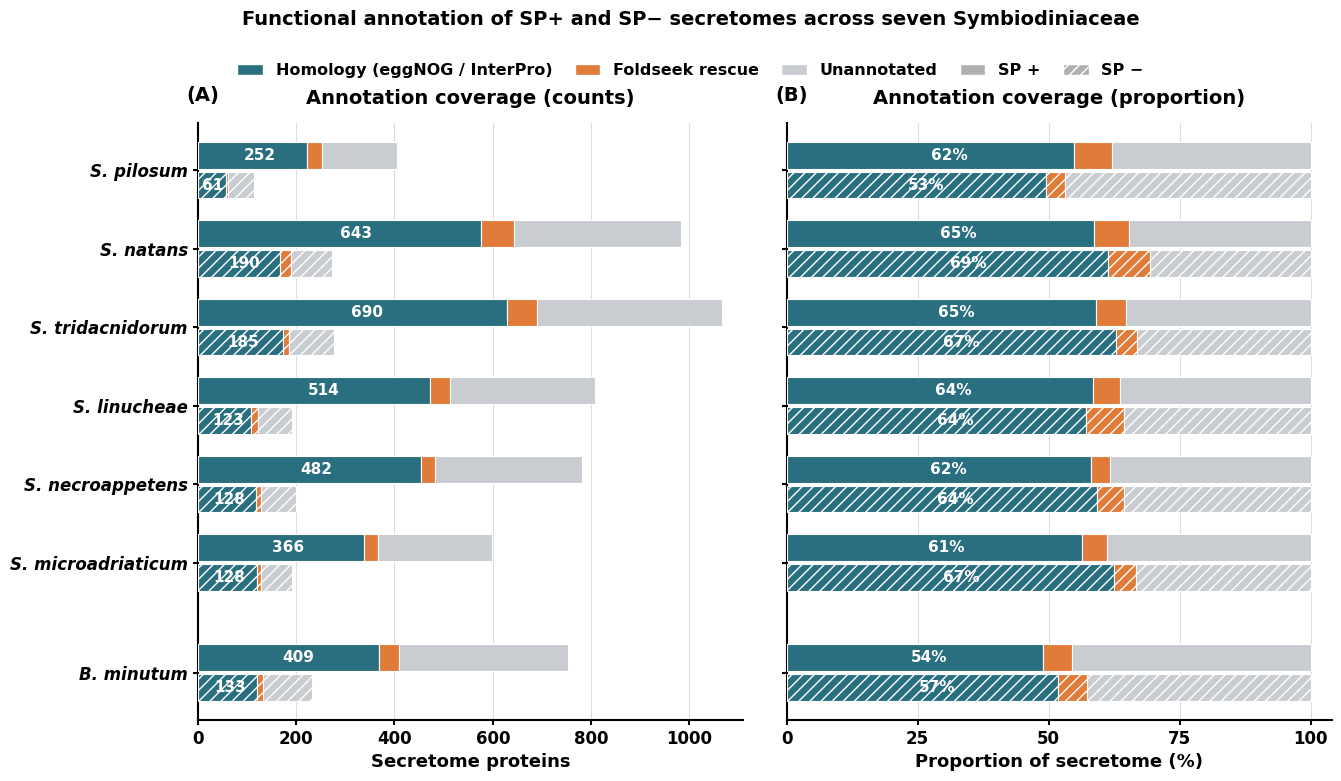

Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/secretome_annotation_coverage.png
Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/secretome_annotation_coverage.svg
Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/secretome_annotation_coverage.pdf


In [ ]:
# =========================================================
# Secretome annotation coverage — 7 strains, SP+ / SP- paired
#   homology (eggNOG/InterPro) -> Foldseek rescue -> unannotated
#   horizontal stacked bars; SP+ solid, SP- hatched; shared y-axis
#   inside labels: n1 = homology+rescue, n2 = unannotated
# =========================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

try: BASE
except NameError: BASE = base
outdir = os.path.join(BASE, "Publication", "data_pre")
figdir = os.path.join(BASE, "Publication", "figures_pre")
os.makedirs(figdir, exist_ok=True)

summary = pd.read_csv(os.path.join(outdir, "ALL_secretome_annotation_summary.tsv"), sep="\t")

STRAINS = ["Spil","Snat","Stri","Slin","Snec","Smic","Bmin"]      # top -> bottom
SPP = {"Spil":"S. pilosum","Snat":"S. natans","Stri":"S. tridacnidorum",
       "Slin":"S. linucheae","Snec":"S. necroappetens","Smic":"S. microadriaticum",
       "Bmin":"B. minutum"}
CATS   = ["homology","foldseek_rescue","unannotated"]
LABELS = ["Homology (eggNOG / InterPro)","Foldseek rescue","Unannotated"]
COLORS = ["#2A6F7F","#E07B39","#C9CDD2"]        # teal, warm orange, light grey
GAP, BARH, OFF = 0.4, 0.34, 0.19
PAIRS = [("SP_pos", -OFF, ""), ("SP_neg", OFF, "///")]

S = summary.set_index(["strain","sp_class"])
def val(s, cls, col):
    return float(S.loc[(s,cls), col]) if (s,cls) in S.index else 0.0

# y positions (clade gap after Smic) ----------------------------------
ypos, y = [], 0.0
for s in STRAINS:
    ypos.append(y); y += 1.0 + (GAP if s == "Smic" else 0.0)
ypos = np.array(ypos)

MAXCOUNT = max(sum(val(s,cls,c) for c in CATS) for s in STRAINS for cls in ["SP_pos","SP_neg"])

plt.rcParams.update({
    "font.size": 12, "font.family": "DejaVu Sans", "font.weight": "bold",
    "axes.labelweight": "bold", "axes.titleweight": "bold", "pdf.fonttype": 42,
})

fig, (axL, axR) = plt.subplots(1, 2, figsize=(13.5, 7.8), sharey=True)

def draw(ax, mode, ylabels=True):                   # mode: "count" | "prop"
    for cls, off, hatch in PAIRS:
        raw = {c: np.array([val(s,cls,c) for s in STRAINS]) for c in CATS}
        tot = sum(raw[c] for c in CATS)
        seg = raw if mode=="count" else \
              {c: np.divide(raw[c], tot, out=np.zeros_like(tot), where=tot>0)*100 for c in CATS}
        # segments
        left = np.zeros(len(STRAINS))
        for cat, color in zip(CATS, COLORS):
            ax.barh(ypos+off, seg[cat], BARH, left=left, color=color,
                    edgecolor="white", linewidth=0.8, hatch=hatch, zorder=3)
            left += seg[cat]
        # inside label: annotated only (homology + rescue)
        annot = seg["homology"] + seg["foldseek_rescue"]
        for i in range(len(STRAINS)):
            if annot[i] > 0:
                t = f"{int(round(annot[i]))}" if mode=="count" else f"{annot[i]:.0f}%"
                ax.text(annot[i]/2, ypos[i]+off, t, ha="center", va="center",
                        fontsize=11, fontweight="bold", color="white", zorder=4)
    ax.set_yticks(ypos)
    ax.set_yticklabels([SPP[s] for s in STRAINS], fontstyle="italic",
                       fontweight="bold", fontsize=12)
    ax.tick_params(labelleft=ylabels)
    ax.set_ylim(ypos.max()+0.6, ypos.min()-0.6)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    for side in ("left","bottom"):
        ax.spines[side].set_visible(True); ax.spines[side].set_linewidth(1.5)
    ax.tick_params(width=1.5)
    ax.set_axisbelow(True); ax.grid(axis="x", color="#DDDDDD", linewidth=0.8, zorder=0)

draw(axL, "count", ylabels=True)
axL.set_xlim(0, MAXCOUNT*1.04)
axL.set_xlabel("Secretome proteins", fontsize=13)
axL.set_title("Annotation coverage (counts)", fontsize=14, pad=14)
axL.text(-0.02, 1.03, "(A)", transform=axL.transAxes, fontsize=14, fontweight="bold",
         va="bottom", ha="left")

draw(axR, "prop", ylabels=False)
axR.set_xlim(0, 104); axR.set_xticks([0,25,50,75,100])
axR.set_xlabel("Proportion of secretome (%)", fontsize=13)
axR.set_title("Annotation coverage (proportion)", fontsize=14, pad=14)
axR.text(-0.02, 1.03, "(B)", transform=axR.transAxes, fontsize=14, fontweight="bold",
         va="bottom", ha="left")

# ── shared legend: categories + SP class ──────────────────────────────
cat_h = [Patch(facecolor=c, edgecolor="white", label=l) for c, l in zip(COLORS, LABELS)]
cls_h = [Patch(facecolor="#B0B0B0", edgecolor="white", label="SP +"),
         Patch(facecolor="#B0B0B0", edgecolor="white", hatch="///", label="SP −")]
leg = fig.legend(handles=cat_h+cls_h, loc="upper center", ncol=5, frameon=False,
                 bbox_to_anchor=(0.5, 0.945), fontsize=11.5, columnspacing=1.4, handlelength=1.6)
for t in leg.get_texts(): t.set_fontweight("bold")

fig.suptitle("Functional annotation of SP+ and SP− secretomes across seven Symbiodiniaceae",
             fontsize=14, y=0.995, fontweight="bold")
fig.subplots_adjust(left=0.135, right=0.975, top=0.85, bottom=0.085, wspace=0.08)

png = os.path.join(figdir, "secretome_annotation_coverage.png")
svg = os.path.join(figdir, "secretome_annotation_coverage.svg")
pdf = os.path.join(figdir, "secretome_annotation_coverage.pdf")
fig.savefig(png, dpi=600, bbox_inches="tight")
fig.savefig(svg, bbox_inches="tight")
fig.savefig(pdf, bbox_inches="tight")
plt.show()
for p in (png, svg, pdf): print("Saved:", p)

## 2.. - MS-detected exoproteins

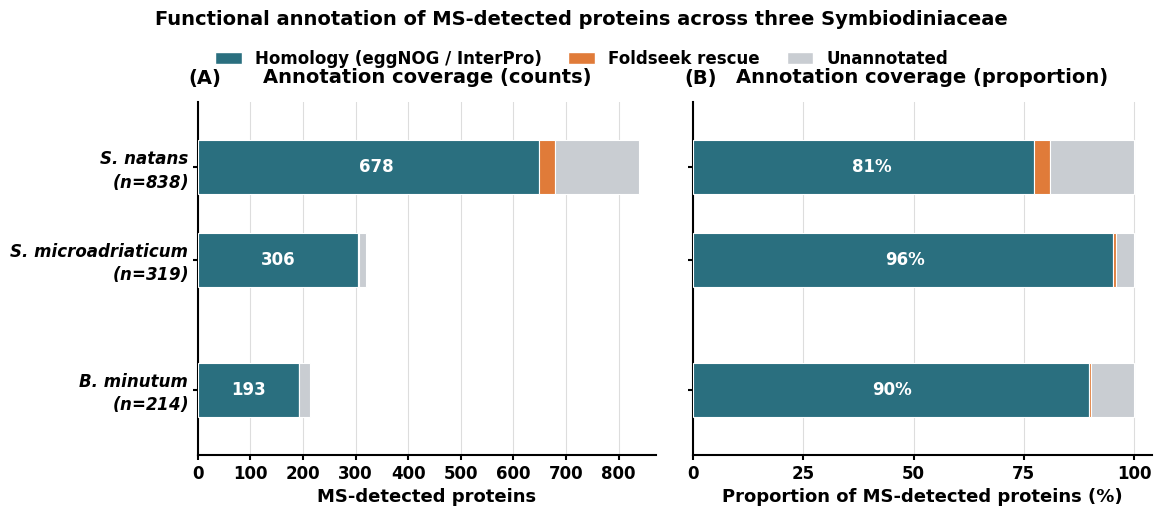

Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/MS_annotation_coverage_horizontal.png
Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/MS_annotation_coverage_horizontal.svg
Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/MS_annotation_coverage_horizontal.pdf


In [ ]:
# =========================================================
# MS-detected protein annotation coverage — 3 strains, horizontal
#   homology (eggNOG/InterPro) -> Foldseek rescue -> unannotated
#   single stacked bar per strain; shared y-axis
#   inside label: annotated (homology + rescue)
# =========================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

try: BASE
except NameError: BASE = base
outdir = os.path.join(BASE, "Publication", "data_pre")
figdir = os.path.join(BASE, "Publication", "figures_pre")
os.makedirs(figdir, exist_ok=True)

summary = pd.read_csv(os.path.join(outdir, "ALL_MS_annotation_summary.tsv"), sep="\t").set_index("strain")

STRAINS = ["Snat", "Smic", "Bmin"]              # phylogenetic order, top -> bottom
SPP = {"Snat":"S. natans","Smic":"S. microadriaticum","Bmin":"B. minutum"}
CATS   = ["homology","foldseek_rescue","unannotated"]
LABELS = ["Homology (eggNOG / InterPro)","Foldseek rescue","Unannotated"]
COLORS = ["#2A6F7F","#E07B39","#C9CDD2"]        # teal, warm orange, light grey
GAP, BARH = 0.4, 0.58

counts = summary.loc[STRAINS, CATS].astype(int)
totals = counts.sum(axis=1)
MAXCOUNT = int(totals.max())

# y positions (clade gap after Smic, before Bmin) ---------------------
ypos, y = [], 0.0
for s in STRAINS:
    ypos.append(y); y += 1.0 + (GAP if s == "Smic" else 0.0)
ypos = np.array(ypos)

ylabels = [f"{SPP[s]}\n($\\boldsymbol{{n}}$={int(totals[s]):,})" for s in STRAINS]

plt.rcParams.update({
    "font.size": 12, "font.family": "DejaVu Sans", "font.weight": "bold",
    "axes.labelweight": "bold", "axes.titleweight": "bold", "pdf.fonttype": 42,
})

fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

def draw(ax, mode, show_ylabels=True):              # mode: "count" | "prop"
    raw = {c: counts[c].values.astype(float) for c in CATS}
    tot = sum(raw[c] for c in CATS)
    seg = raw if mode=="count" else \
          {c: np.divide(raw[c], tot, out=np.zeros_like(tot), where=tot>0)*100 for c in CATS}
    left = np.zeros(len(STRAINS))
    for cat, color in zip(CATS, COLORS):
        ax.barh(ypos, seg[cat], BARH, left=left, color=color,
                edgecolor="white", linewidth=0.8, zorder=3)
        left += seg[cat]
    # inside label: annotated only (homology + rescue)
    annot = seg["homology"] + seg["foldseek_rescue"]
    for i in range(len(STRAINS)):
        if annot[i] > 0:
            t = f"{int(round(annot[i])):,}" if mode=="count" else f"{annot[i]:.0f}%"
            ax.text(annot[i]/2, ypos[i], t, ha="center", va="center",
                    fontsize=12, fontweight="bold", color="white", zorder=4)
    ax.set_yticks(ypos)
    ax.set_yticklabels(ylabels, fontstyle="italic", fontweight="bold", fontsize=12)
    ax.tick_params(labelleft=show_ylabels, width=1.5)
    ax.set_ylim(ypos.max()+0.7, ypos.min()-0.7)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    for side in ("left","bottom"):
        ax.spines[side].set_visible(True); ax.spines[side].set_linewidth(1.5)
    ax.set_axisbelow(True); ax.grid(axis="x", color="#DDDDDD", linewidth=0.8, zorder=0)

draw(axL, "count", show_ylabels=True)
axL.set_xlim(0, MAXCOUNT*1.04)
axL.set_xlabel("MS-detected proteins", fontsize=13)
axL.set_title("Annotation coverage (counts)", fontsize=14, pad=14)
axL.text(-0.02, 1.04, "(A)", transform=axL.transAxes, fontsize=14, fontweight="bold",
         va="bottom", ha="left")

draw(axR, "prop", show_ylabels=False)
axR.set_xlim(0, 104); axR.set_xticks([0,25,50,75,100])
axR.set_xlabel("Proportion of MS-detected proteins (%)", fontsize=13)
axR.set_title("Annotation coverage (proportion)", fontsize=14, pad=14)
axR.text(-0.02, 1.04, "(B)", transform=axR.transAxes, fontsize=14, fontweight="bold",
         va="bottom", ha="left")

# ── shared legend ─────────────────────────────────────────────────────
handles = [Patch(facecolor=c, edgecolor="white", label=l) for c, l in zip(COLORS, LABELS)]
leg = fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False,
                 bbox_to_anchor=(0.5, 0.955), fontsize=12, columnspacing=1.6, handlelength=1.6)
for t in leg.get_texts(): t.set_fontweight("bold")

fig.suptitle("Functional annotation of MS-detected proteins across three Symbiodiniaceae",
             fontsize=14, y=1.005, fontweight="bold")
fig.subplots_adjust(left=0.18, right=0.975, top=0.82, bottom=0.115, wspace=0.08)

png = os.path.join(figdir, "MS_annotation_coverage_horizontal.png")
svg = os.path.join(figdir, "MS_annotation_coverage_horizontal.svg")
pdf = os.path.join(figdir, "MS_annotation_coverage_horizontal.pdf")
fig.savefig(png, dpi=600, bbox_inches="tight")
fig.savefig(svg, bbox_inches="tight")
fig.savefig(pdf, bbox_inches="tight")
plt.show()
for p in (png, svg, pdf): print("Saved:", p)

# 3 - Enrichment analysis

## 3.1 - Pfam

In [ ]:
# ============================================================
# BLOCK A: Build Pfam_final for the WHOLE PROTEOME (secreted +
# non-secreted together, one gene = one row), using eggNOG +
# InterPro + Foldseek rescue.
#
# FULLY SELF-CONTAINED - builds the gene universe and secreted/
# non-secreted sets itself, same as your original secretome-merge
# script. No dependency on any other cell having been run first.
#
# FIX: clean_protein_id's Smic_jgi branch matches the established,
# validated normalize_id() logic (split on first 3 underscores,
# join with pipes, keep the 4th segment underscore-prefixed) - NOT
# pid.replace("_","|",3), which produced zero ID matches.
# ============================================================

import os, re, gc
import numpy as np
import pandas as pd
from io import StringIO

STRAINS = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic_jgi", "Bmin"]

ANN = os.path.join(base, "8_Annotation_results")
DATA_PRE = os.path.join(base, "Publication", "data_pre")
os.makedirs(DATA_PRE, exist_ok=True)

ORTHO_ROOT = os.path.join(base, "9_Ortholog_analysis")
ORTHOGROUPS_TSV = os.path.join(ORTHO_ROOT, "Pro_OF_dendroblast", "Orthogroups", "Orthogroups.tsv")
UNASSIGNED_TSV = os.path.join(ORTHO_ROOT, "Pro_OF_dendroblast", "Orthogroups", "Orthogroups_UnassignedGenes.tsv")
SECRETOME_ROOT = os.path.join(base, "Prediction_vs_Detection")

EGGNOG_FILE = lambda s: os.path.join(ANN, "Smic_jgi.emapper.annotations") if s == "Smic_jgi" \
                        else os.path.join(ANN, f"{s}_background_eggnog.emapper.annotations")
INTERPRO_FILE = lambda s: os.path.join(ANN, "Symmic_jgi_noStar.faa.tsv") if s == "Smic_jgi" \
                          else os.path.join(ANN, f"{s}_background_interproscan.tsv")
FOLDSEEK_FILE = lambda s: os.path.join(ANN, "Symmic_jgi_noStar_jgi_foldseek_hits.tsv") if s == "Smic_jgi" \
                          else os.path.join(ANN, f"{s}_pro_foldseek_hits.tsv")

FS_EVALUE_MAX, FS_QCOV_MIN, FS_TCOV_MIN = 1e-3, 0.50, 0.50

PF_RE = re.compile(r"PF\d{5}")
BMIN_RE = re.compile(r"(symbB\.v1\.2\.\d{6}\.t\d+)")
AF_RE = re.compile(r"AF-([A-Z0-9]+)-F\d+")
UP_RE = re.compile(r"([A-NR-Z][0-9][A-Z0-9]{3}[0-9]|[OPQ][0-9][A-Z0-9]{3}[0-9])")

def clean_protein_id(pid, strain):
    """Single ID-normalization function used EVERYWHERE in this script.

    Smic_jgi has TWO different raw ID formats across data sources:
      - FASTA/Orthogroups.tsv: underscore-delimited, e.g. jgi_Symmic1_34850_rna24714
      - eggNOG/InterPro/Foldseek: already pipe-delimited, e.g. jgi|Symmic1|10009|rna1393
    Both get converted to the same target format: jgi|Symmic1|NUM_rnaNUM
    """
    if not isinstance(pid, str):
        return pid
    pid = pid.strip()
    if strain == "Smic_jgi":
        if "|" in pid and "_" not in pid:
            # Already pipe-delimited (eggNOG/InterPro/Foldseek) - convert
            # only the LAST pipe to underscore to match target format.
            head, tail = pid.rsplit("|", 1)
            return f"{head}_{tail}"
        elif "_" in pid:
            # Underscore-delimited (FASTA/Orthogroups.tsv) - convert first
            # 3 underscores to pipes, keep last segment underscore-prefixed.
            parts = pid.split("_", 3)
            if len(parts) == 4:
                return "|".join(parts[:3]) + "_" + parts[3]
        return pid
    if strain == "Bmin":
        m = BMIN_RE.search(pid)
        return m.group(1) if m else pid.split("|")[0]
    return pid

def parse_fasta_headers(filepath):
    headers = set()
    if not os.path.exists(filepath):
        return headers
    with open(filepath) as f:
        for line in f:
            if line.startswith(">"):
                headers.add(line[1:].strip().split()[0])
    return headers

# ============================================================
# STEP 0: Build full gene universe + secreted/non-secreted sets
# (self-contained - same logic as the earlier standalone script,
# now inlined here so this block has no external dependency)
# ============================================================
print("=" * 60)
print("STEP 0: Building gene universe and secreted/non-secreted sets")
print("=" * 60)

og = pd.read_csv(ORTHOGROUPS_TSV, sep="\t")
unassigned = pd.read_csv(UNASSIGNED_TSV, sep="\t")

full_gene_universe = {strain: set() for strain in STRAINS}
for df_source in [og, unassigned]:
    for strain in STRAINS:
        if strain not in df_source.columns:
            continue
        for cell in df_source[strain].dropna():
            for gid in str(cell).split(","):
                gid = gid.strip()
                if gid:
                    full_gene_universe[strain].add(clean_protein_id(gid, strain))

secreted_genes = {strain: set() for strain in STRAINS}
for strain in STRAINS:
    sp_pos_path = os.path.join(SECRETOME_ROOT, strain, "09_final", f"{strain}_SP_pos_secretome_final.faa")
    sp_neg_path = os.path.join(SECRETOME_ROOT, strain, "09_final", f"{strain}_SP_neg_secretome_final.faa")
    for gid in parse_fasta_headers(sp_pos_path) | parse_fasta_headers(sp_neg_path):
        secreted_genes[strain].add(clean_protein_id(gid, strain))

non_secreted_genes = {strain: full_gene_universe[strain] - secreted_genes[strain] for strain in STRAINS}

for strain in STRAINS:
    print(f"[CHECK] {strain}: universe={len(full_gene_universe[strain])}, "
          f"secreted={len(secreted_genes[strain])}, "
          f"non_secreted={len(non_secreted_genes[strain])}")

def collect_tokens(rgx, *cells):
    s = set()
    for c in cells:
        if isinstance(c, str) and c and c != "-":
            s.update(rgx.findall(c))
    return ",".join(sorted(s))

def extract_af_accession(t):
    if not isinstance(t, str):
        return None
    m = AF_RE.search(t)
    m2 = UP_RE.search(t)
    return m.group(1) if m else (m2.group(1) if m2 else None)

def load_eggnog_pfam(strain):
    path = EGGNOG_FILE(strain)
    if not os.path.exists(path):
        print(f"    [WARN] eggNOG missing: {path}")
        return pd.DataFrame(columns=["protein_id", "eggnog_Pfam"])
    with open(path) as fh:
        lines = [l for l in fh if not l.startswith("##")]
    egg = pd.read_csv(StringIO("".join(lines)), sep="\t", dtype=str)
    egg = egg.rename(columns={"#query": "query"})
    keep = {"query": "protein_id", "PFAMs": "eggnog_Pfam"}
    egg = egg[[c for c in keep if c in egg.columns]].rename(columns=keep)
    egg["protein_id"] = egg["protein_id"].map(lambda x: clean_protein_id(x, strain))
    if "eggnog_Pfam" in egg:
        egg["eggnog_Pfam"] = egg["eggnog_Pfam"].replace("-", np.nan)
    return egg.drop_duplicates("protein_id")

IPR_COLS = ["acc", "md5", "len", "analysis", "sig_acc", "sig_desc", "start", "stop",
            "score", "status", "date", "ipr_acc", "ipr_desc", "go", "pathways"]

def load_interpro_raw(strain):
    path = INTERPRO_FILE(strain)
    if not os.path.exists(path):
        print(f"    [WARN] InterPro missing: {path}")
        return pd.DataFrame(columns=IPR_COLS)
    rows = []
    with open(path) as fh:
        for line in fh:
            line = line.rstrip("\n")
            if not line:
                continue
            p = line.split("\t")
            p += [""] * (15 - len(p))
            rows.append(p[:15])
    ip = pd.DataFrame(rows, columns=IPR_COLS)
    ip["acc"] = ip["acc"].map(lambda x: clean_protein_id(x, strain))
    return ip

def get_interpro_hit_ids(ip_raw, id_set):
    if ip_raw.empty:
        return set()
    return set(ip_raw[ip_raw["acc"].isin(id_set)]["acc"].unique())

def aggregate_interpro_pfam(ip_raw, id_set):
    if ip_raw.empty:
        return pd.DataFrame(columns=["protein_id", "interpro_Pfam"])
    sub = ip_raw[ip_raw["acc"].isin(id_set)]
    if sub.empty:
        return pd.DataFrame(columns=["protein_id", "interpro_Pfam"])
    def agg(g):
        pf = sorted({a for a, an in zip(g["sig_acc"], g["analysis"])
                     if an == "Pfam" and isinstance(a, str) and a.startswith("PF")})
        return pd.Series({"interpro_Pfam": ",".join(pf)})
    out = (sub.groupby("acc", sort=False)[["sig_acc", "analysis"]]
              .apply(agg).reset_index())
    return out.rename(columns={"acc": "protein_id"})

FS7 = ["query", "target", "evalue", "pident", "alnlen", "qcov", "tcov"]

def load_foldseek(strain):
    path = FOLDSEEK_FILE(strain)
    if not os.path.exists(path):
        print(f"    [WARN] Foldseek missing: {path}")
        return pd.DataFrame(columns=["protein_id", "target"])
    with open(path) as fh:
        ncol = len(fh.readline().rstrip("\n").split("\t"))
    cols = FS7 + ["tmscore"] if ncol >= 8 else FS7
    fs = pd.read_csv(path, sep="\t", header=None, names=cols[:ncol], dtype=str)
    for c in ("evalue", "pident", "alnlen", "qcov", "tcov"):
        if c in fs:
            fs[c] = pd.to_numeric(fs[c], errors="coerce")
    fs["query"] = fs["query"].map(lambda x: clean_protein_id(x, strain))
    fs = fs.sort_values("evalue").drop_duplicates("query", keep="first")
    return fs.rename(columns={"query": "protein_id"})

def pass_rescue_cutoff(sub):
    return ((sub["evalue"] <= FS_EVALUE_MAX) &
            (sub["qcov"].fillna(0) >= FS_QCOV_MIN) &
            (sub["tcov"].fillna(0) >= FS_TCOV_MIN))

def _load_sprot_map():
    cand = [os.path.join(ANN, "uniprot_sprot_annotation_map.tsv"),
            os.path.join(DATA_PRE, "uniprot_sprot_annotation_map.tsv")]
    path = next((p for p in cand if os.path.exists(p)), None)
    if path is None:
        print("[WARN] uniprot_sprot_annotation_map.tsv not found - Foldseek hits "
              "will be flagged but Pfam not transferred.")
        return None
    raw = pd.read_csv(path, sep="\t", dtype=str)
    if "foldseek_uniprot_acc" in raw.columns:
        m = raw[["foldseek_uniprot_acc", "Pfam"]].rename(columns={"Pfam": "foldseek_Pfam"}) \
            if "Pfam" in raw.columns else raw
    else:
        frames = []
        for keycol in ("From", "Entry"):
            if keycol in raw.columns:
                sub = raw.rename(columns={"Pfam": "foldseek_Pfam"}).copy()
                sub["foldseek_uniprot_acc"] = raw[keycol]
                if "foldseek_Pfam" not in sub.columns:
                    sub["foldseek_Pfam"] = np.nan
                frames.append(sub[["foldseek_uniprot_acc", "foldseek_Pfam"]])
        if not frames:
            print(f"[WARN] map at {path} lacks expected columns; columns={list(raw.columns)}")
            return None
        m = (pd.concat(frames, ignore_index=True)
               .dropna(subset=["foldseek_uniprot_acc"])
               .drop_duplicates("foldseek_uniprot_acc"))
    print(f"[CHECK] Swiss-Prot map: {len(m):,} accessions | source: {os.path.basename(path)}")
    return m

SPROT = _load_sprot_map()

# ============================================================
# Build WHOLE-PROTEOME Pfam_final per strain (all genes, one pass)
# ============================================================
whole_proteome_pfam_records = []

for strain in STRAINS:
    all_ids = full_gene_universe[strain]
    print(f"\n[{strain}] building whole-proteome Pfam_final for {len(all_ids)} genes")

    egg = load_eggnog_pfam(strain)
    egg_hit = egg[egg["protein_id"].isin(all_ids)]
    egg_hit_ids = set(egg_hit["protein_id"])
    print(f"  eggNOG hits: {len(egg_hit_ids)}")

    ipr_raw = load_interpro_raw(strain)
    ipr_hit_ids = get_interpro_hit_ids(ipr_raw, all_ids)
    ipr_agg = aggregate_interpro_pfam(ipr_raw, all_ids)
    print(f"  InterPro hits (any db): {len(ipr_hit_ids)}")

    fs_only_ids = all_ids - egg_hit_ids - ipr_hit_ids
    print(f"  Rescue candidates (no eggNOG, no InterPro): {len(fs_only_ids)} "
          f"({100*len(fs_only_ids)/len(all_ids):.1f}%)")

    fs = load_foldseek(strain)
    fs_sub = fs[fs["protein_id"].isin(fs_only_ids)].copy()
    if not fs_sub.empty:
        fs_sub["passes_rescue"] = pass_rescue_cutoff(fs_sub)
        fs_rescued = fs_sub[fs_sub["passes_rescue"]].copy()
    else:
        fs_rescued = fs_sub.copy()
        fs_rescued["passes_rescue"] = pd.Series(dtype=bool)

    print(f"  Foldseek hits among rescue candidates: {len(fs_sub)}; "
          f"passing rescue cutoff: {len(fs_rescued)}")

    fs_rescued["foldseek_uniprot_acc"] = fs_rescued["target"].map(extract_af_accession)
    if SPROT is not None and not fs_rescued.empty:
        fs_rescued = fs_rescued.merge(SPROT, on="foldseek_uniprot_acc", how="left")
    if "foldseek_Pfam" not in fs_rescued.columns:
        fs_rescued["foldseek_Pfam"] = np.nan

    n_rescued_with_pfam = fs_rescued["foldseek_Pfam"].notna().sum()
    print(f"  Rescued genes gaining a Pfam call via Swiss-Prot transfer: {n_rescued_with_pfam}")

    merged = pd.DataFrame({"protein_id": sorted(all_ids)})
    merged = merged.merge(egg_hit[["protein_id", "eggnog_Pfam"]], on="protein_id", how="left")
    merged = merged.merge(ipr_agg, on="protein_id", how="left")
    merged = merged.merge(fs_rescued[["protein_id", "foldseek_Pfam"]], on="protein_id", how="left")

    merged["Pfam_final"] = [
        collect_tokens(PF_RE, a, b, c)
        for a, b, c in zip(merged.get("eggnog_Pfam", pd.Series([np.nan]*len(merged))),
                            merged.get("interpro_Pfam", pd.Series([np.nan]*len(merged))),
                            merged.get("foldseek_Pfam", pd.Series([np.nan]*len(merged))))
    ]

    n_annot = (merged["Pfam_final"].str.len() > 0).sum()
    print(f"  -> {n_annot}/{len(merged)} genes have >=1 Pfam domain "
          f"({100*n_annot/len(merged):.1f}%)")

    merged["strain"] = strain
    whole_proteome_pfam_records.append(merged[["strain", "protein_id", "Pfam_final"]])

    del egg, egg_hit, ipr_raw, ipr_agg, fs, fs_sub, fs_rescued, merged
    gc.collect()

whole_proteome_pfam_df = pd.concat(whole_proteome_pfam_records, ignore_index=True)
out_path = os.path.join(DATA_PRE, "ALL_whole_proteome_Pfam_final.tsv")
whole_proteome_pfam_df.to_csv(out_path, sep="\t", index=False)
print(f"\n[SAVED] {out_path}")
print(whole_proteome_pfam_df.head(10))

STEP 0: Building gene universe and secreted/non-secreted sets
[CHECK] Spil: universe=23249, secreted=521, non_secreted=22728
[CHECK] Snat: universe=34375, secreted=1257, non_secreted=33118
[CHECK] Stri: universe=41779, secreted=1343, non_secreted=40436
[CHECK] Slin: universe=32002, secreted=998, non_secreted=31004
[CHECK] Snec: universe=35566, secreted=981, non_secreted=34585
[CHECK] Smic_jgi: universe=42915, secreted=791, non_secreted=42124
[CHECK] Bmin: universe=45245, secreted=984, non_secreted=44261
[CHECK] Swiss-Prot map: 5,575 accessions | source: uniprot_sprot_annotation_map.tsv

[Spil] building whole-proteome Pfam_final for 23249 genes
  eggNOG hits: 12136
  InterPro hits (any db): 18239
  Rescue candidates (no eggNOG, no InterPro): 4352 (18.7%)
  Foldseek hits among rescue candidates: 3779; passing rescue cutoff: 317
  Rescued genes gaining a Pfam call via Swiss-Prot transfer: 124
  -> 10819/23249 genes have >=1 Pfam domain (46.5%)

[Snat] building whole-proteome Pfam_final fo

[CHECK] Total unique Pfam domains observed: 6158
[CHECK] Total domain-gene occurrences: 169561
[CHECK] Median domain occurrence count: 6.0
[CHECK] Domains occurring exactly once: 960 (15.6% of all domains)

Threshold sensitivity:
Threshold   Domains passing   % of domains   % of occurrences retained
1           6158              100.0          100.0                    
2           5198              84.4           99.4                     
3           4589              74.5           98.7                     
5           3779              61.4           97.0                     
10          2356              38.3           91.5                     
15          1724              28.0           87.1                     
20          1385              22.5           83.8                     
30          950               15.4           77.6                     
50          608               9.9            70.0                     
100         290               4.7            57.2           

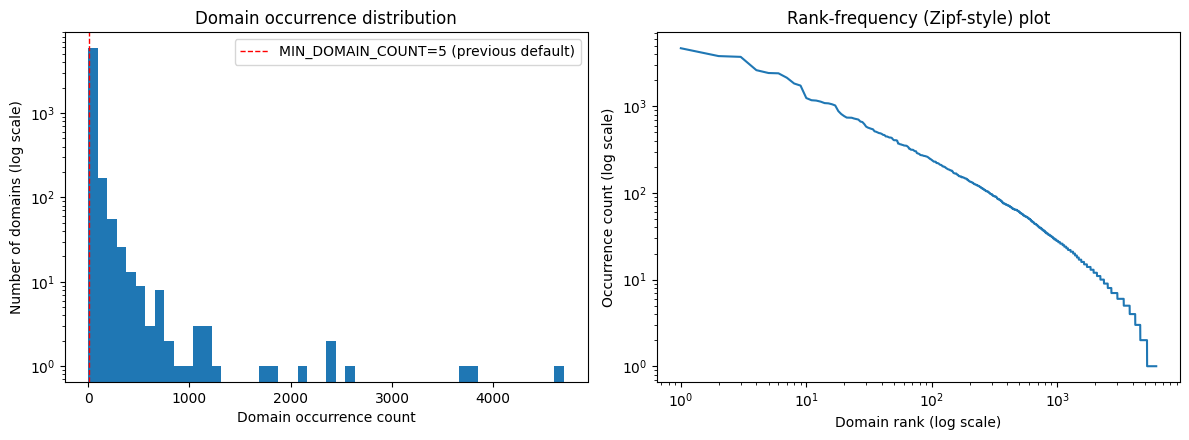


[NEXT STEP] Pick a MIN_DOMAIN_COUNT for Block C based on the table above - e.g., a threshold that keeps most total occurrences while dropping the singleton/near-singleton tail that can't give a stable odds ratio.


In [ ]:
# ============================================================
# BLOCK B: DIAGNOSTIC - Pfam domain occurrence distribution
#
# Purely exploratory - makes no filtering decisions itself. Informs
# what MIN_DOMAIN_COUNT to use in Block C (enrichment test), based
# on where YOUR data's actual long tail sits, rather than an
# arbitrary round number.
# ============================================================

import os
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

DATA_PRE = os.path.join(base, "Publication", "data_pre")

whole_proteome_pfam_df = pd.read_csv(
    os.path.join(DATA_PRE, "ALL_whole_proteome_Pfam_final.tsv"), sep="\t"
)
whole_proteome_pfam_df["Pfam_final"] = whole_proteome_pfam_df["Pfam_final"].fillna("")

# ============================================================
# Count total occurrences per domain, across the WHOLE proteome
# (secreted + background combined - this equals a+c in Block C's
# contingency table, so it's exactly what MIN_DOMAIN_COUNT filters on)
# ============================================================
domain_counts = Counter()
for pfam_str in whole_proteome_pfam_df["Pfam_final"]:
    if pfam_str:
        domain_counts.update(pfam_str.split(","))

counts = pd.Series(domain_counts).sort_values(ascending=False)
n_domains = len(counts)
total_occurrences = int(counts.sum())

print(f"[CHECK] Total unique Pfam domains observed: {n_domains}")
print(f"[CHECK] Total domain-gene occurrences: {total_occurrences}")
print(f"[CHECK] Median domain occurrence count: {counts.median():.1f}")
print(f"[CHECK] Domains occurring exactly once: {(counts == 1).sum()} "
      f"({100*(counts == 1).sum()/n_domains:.1f}% of all domains)")

# ============================================================
# Threshold sensitivity table - the actual decision-making tool
# ============================================================
print("\nThreshold sensitivity:")
print(f"{'Threshold':<12}{'Domains passing':<18}{'% of domains':<15}{'% of occurrences retained':<25}")
for thresh in [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]:
    passing = counts[counts >= thresh]
    n_pass = len(passing)
    pct_domains = 100 * n_pass / n_domains
    pct_occurrences = 100 * passing.sum() / total_occurrences
    print(f"{thresh:<12}{n_pass:<18}{pct_domains:<15.1f}{pct_occurrences:<25.1f}")

# ============================================================
# Diagnostic plots (exploratory only - NOT publication figures,
# using tight_layout deliberately since this isn't a fixed-layout
# deliverable like the other figures in this project)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(counts, bins=50)
axes[0].set_yscale("log")
axes[0].set_xlabel("Domain occurrence count")
axes[0].set_ylabel("Number of domains (log scale)")
axes[0].set_title("Domain occurrence distribution")
axes[0].axvline(5, color="red", linestyle="--", linewidth=1, label="MIN_DOMAIN_COUNT=5 (previous default)")
axes[0].legend()

axes[1].plot(range(1, len(counts) + 1), counts.values)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Domain rank (log scale)")
axes[1].set_ylabel("Occurrence count (log scale)")
axes[1].set_title("Rank-frequency (Zipf-style) plot")

plt.tight_layout()
plt.show()

print("\n[NEXT STEP] Pick a MIN_DOMAIN_COUNT for Block C based on the table above - "
      "e.g., a threshold that keeps most total occurrences while dropping the "
      "singleton/near-singleton tail that can't give a stable odds ratio.")

In [ ]:
# ============================================================
# BLOCK C: Pfam domain enrichment - secretome vs non-secretome
#
# Uses the unified whole-proteome Pfam_final table from Block A,
# split into secreted / non-secreted groups using the secreted_genes
# and non_secreted_genes sets already built in Block A. Splitting
# happens HERE, once, from ONE annotation source - not via two
# separately-built pipelines.
#
# MIN_DOMAIN_COUNT: set based on Block B's threshold sensitivity
# table, not an arbitrary default.
# ============================================================

import os
import pandas as pd
import numpy as np
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
from collections import Counter

try:
    secreted_genes, non_secreted_genes
except NameError:
    raise RuntimeError(
        "secreted_genes / non_secreted_genes not defined - run Block A "
        "(the whole-proteome Pfam_final build) in this same session first."
    )

DATA_PRE = os.path.join(base, "Publication", "data_pre")
MIN_DOMAIN_COUNT = 5

whole_proteome_pfam_df = pd.read_csv(
    os.path.join(DATA_PRE, "ALL_whole_proteome_Pfam_final.tsv"), sep="\t"
)
whole_proteome_pfam_df["Pfam_final"] = whole_proteome_pfam_df["Pfam_final"].fillna("")
print(f"[CHECK] Whole-proteome table loaded: {whole_proteome_pfam_df.shape[0]} genes")

# ============================================================
# STEP 1: Split into secreted / non-secreted using existing sets
# ============================================================
def get_group(row):
    gid, strain = row["protein_id"], row["strain"]
    if gid in secreted_genes[strain]:
        return "secreted"
    elif gid in non_secreted_genes[strain]:
        return "non_secreted"
    else:
        return "unmatched"

whole_proteome_pfam_df["group"] = whole_proteome_pfam_df.apply(get_group, axis=1)
print(whole_proteome_pfam_df["group"].value_counts())

n_unmatched = (whole_proteome_pfam_df["group"] == "unmatched").sum()
if n_unmatched > 0:
    print(f"[WARNING] {n_unmatched} genes matched neither secreted_genes nor "
          f"non_secreted_genes - check ID consistency before trusting results.")

secreted_df = whole_proteome_pfam_df[whole_proteome_pfam_df["group"] == "secreted"]
background_df = whole_proteome_pfam_df[whole_proteome_pfam_df["group"] == "non_secreted"]

# ============================================================
# STEP 2: Build domain sets and counts per group
# ============================================================
def build_domain_sets(df):
    out = {}
    for pid, pfam_str in zip(df["protein_id"], df["Pfam_final"]):
        out[pid] = set(pfam_str.split(",")) if pfam_str else set()
    return out

secreted_domains = build_domain_sets(secreted_df)
background_domains = build_domain_sets(background_df)

n_secreted = len(secreted_domains)
n_background = len(background_domains)
print(f"[CHECK] n_secreted={n_secreted}, n_background={n_background}")

secreted_domain_counts = Counter()
for domains in secreted_domains.values():
    secreted_domain_counts.update(domains)

background_domain_counts = Counter()
for domains in background_domains.values():
    background_domain_counts.update(domains)

all_domains = set(secreted_domain_counts) | set(background_domain_counts)
all_domains.discard("")
print(f"[CHECK] Total unique Pfam domains observed: {len(all_domains)}")

# ============================================================
# STEP 3: Fisher's exact test per domain
# ============================================================
results = []
for domain in all_domains:
    a = secreted_domain_counts.get(domain, 0)
    b = n_secreted - a
    c = background_domain_counts.get(domain, 0)
    d = n_background - c

    if (a + c) < MIN_DOMAIN_COUNT:
        continue

    odds_ratio, p_value = fisher_exact([[a, b], [c, d]], alternative="two-sided")
    results.append({
        "pfam_domain": domain,
        "secreted_with": a, "secreted_without": b,
        "background_with": c, "background_without": d,
        "odds_ratio": odds_ratio, "p_value": p_value,
    })

results_df = pd.DataFrame(results)
print(f"\n[CHECK] Domains tested (>= {MIN_DOMAIN_COUNT} total occurrences): {results_df.shape[0]}")

# ============================================================
# STEP 4: BH-FDR correction
# ============================================================
reject, fdr, _, _ = multipletests(results_df["p_value"], method="fdr_bh")
results_df["fdr"] = fdr
results_df["significant"] = reject
results_df["log2_odds_ratio"] = np.log2(results_df["odds_ratio"].replace(0, np.nan))
results_df["neg_log10_fdr"] = -np.log10(results_df["fdr"].replace(0, 1e-300))
results_df = results_df.sort_values("fdr")

n_sig = results_df["significant"].sum()
print(f"[CHECK] Significant domains (FDR < 0.05): {n_sig}")

out_path = os.path.join(DATA_PRE, "pfam_enrichment_secretome_vs_background.tsv")
results_df.to_csv(out_path, sep="\t", index=False)
print(f"[SAVED] {out_path}")
print("\nTop 10 by FDR:")
print(results_df[["pfam_domain", "secreted_with", "background_with",
                   "odds_ratio", "p_value", "fdr"]].head(10).to_string(index=False))

[CHECK] Whole-proteome table loaded: 255131 genes
group
non_secreted    248256
secreted          6875
Name: count, dtype: int64
[CHECK] n_secreted=6875, n_background=248256
[CHECK] Total unique Pfam domains observed: 6158

[CHECK] Domains tested (>= 5 total occurrences): 3779
[CHECK] Significant domains (FDR < 0.05): 228
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/pfam_enrichment_secretome_vs_background.tsv

Top 10 by FDR:
pfam_domain  secreted_with  background_with  odds_ratio      p_value          fdr
    PF00112             91              262   12.696834 1.180090e-60 4.459559e-57
    PF08246             56               57   35.759588 1.752911e-56 3.312126e-53
    PF00520              0             3734    0.000000 5.897727e-45 7.429170e-42
    PF05050             79              328    8.786693 5.086549e-43 4.805517e-40
    PF13360             46               70   23.882509 4.409253e-41 3.332513e-38
    PF00026             62              289    7.808172 1

[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/pfam_enrichment_volcano.pdf
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/pfam_enrichment_volcano.svg
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/pfam_enrichment_volcano.png


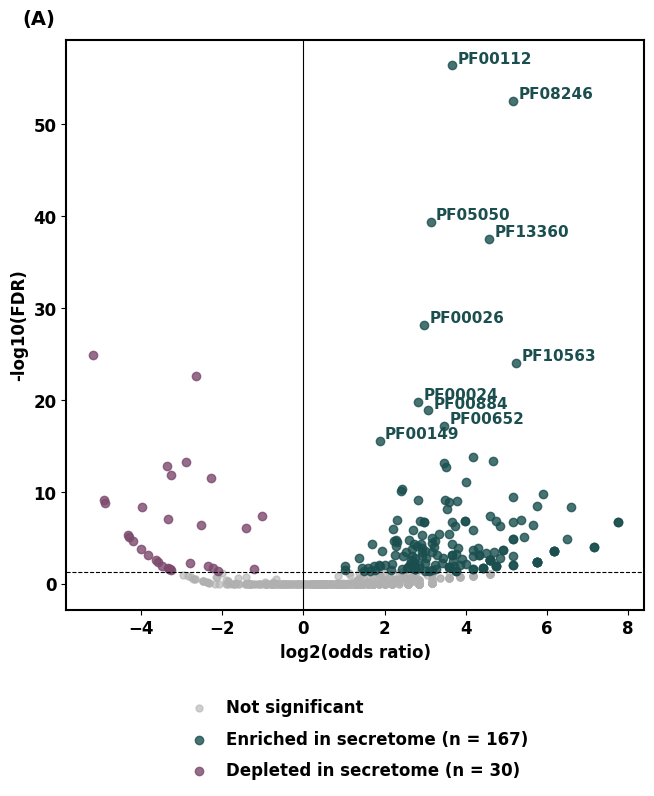

In [ ]:
# ============================================================
# BLOCK D: Visualization - Pfam enrichment volcano plot
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['font.weight'] = 'bold'
mpl.rcParams['axes.labelweight'] = 'bold'
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.size'] = 12

DATA_PRE = os.path.join(base, "Publication", "data_pre")
FIG_DIR = os.path.join(base, "Publication", "figures_pre")
os.makedirs(FIG_DIR, exist_ok=True)

results_df = pd.read_csv(
    os.path.join(DATA_PRE, "pfam_enrichment_secretome_vs_background.tsv"),
    sep="\t"
)

# ------------------------------------------------------------
# Split categories
# ------------------------------------------------------------
sig_up = results_df[
    (results_df["significant"]) & (results_df["log2_odds_ratio"] > 0)
]
sig_down = results_df[
    (results_df["significant"]) & (results_df["log2_odds_ratio"] < 0)
]
not_sig = results_df[~results_df["significant"]]

n_up = sig_up.shape[0]
n_down = sig_down.shape[0]

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6.8, 9.5))   # wider figure

ax.scatter(
    not_sig["log2_odds_ratio"], not_sig["neg_log10_fdr"],
    color="#B0B0B0", s=25, alpha=0.6, label="Not significant"
)
ax.scatter(
    sig_up["log2_odds_ratio"], sig_up["neg_log10_fdr"],
    color="#1B4F4F", s=36, alpha=0.8,
    label=f"Enriched in secretome (n = {n_up})"
)
ax.scatter(
    sig_down["log2_odds_ratio"], sig_down["neg_log10_fdr"],
    color="#7C4A6E", s=36, alpha=0.8,
    label=f"Depleted in secretome (n = {n_down})"
)

# Threshold lines
ax.axhline(-np.log10(0.05), color="black", linewidth=0.8, linestyle="--")
ax.axvline(0, color="black", linewidth=0.8)

# ------------------------------------------------------------
# Label top enriched Pfams
# ------------------------------------------------------------
TOP_LABEL = 10
top = sig_up.nlargest(TOP_LABEL, "neg_log10_fdr")

for _, r in top.iterrows():
    ax.annotate(
        r["pfam_domain"],
        (r["log2_odds_ratio"], r["neg_log10_fdr"]),
        xytext=(4, 2),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color="#1B4F4F"
    )

# ------------------------------------------------------------
# Axes labels
# ------------------------------------------------------------
ax.set_xlabel("log2(odds ratio)", fontweight="bold")
ax.set_ylabel("-log10(FDR)", fontweight="bold")

# ------------------------------------------------------------
# Show counts directly in the panel
# ------------------------------------------------------------

# Panel label
ax.text(
    -0.02, 1.02, "(A)",
    transform=ax.transAxes,
    fontsize=14, fontweight="bold",
    ha="right", va="bottom"
)

# ------------------------------------------------------------
# Legend at bottom
# ------------------------------------------------------------
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    frameon=False,
    ncol=1,
    fontsize=12,
    handletextpad=0.6,
    labelspacing=0.8,
)

for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_visible(True)

plt.subplots_adjust(left=0.12, right=0.97, top=0.92, bottom=0.32)

for ext in ["pdf", "svg", "png"]:
    kwargs = {"dpi": 600} if ext == "png" else {}
    outpath = os.path.join(FIG_DIR, f"pfam_enrichment_volcano.{ext}")
    fig.savefig(outpath, bbox_inches="tight", **kwargs)
    print(f"[SAVED] {outpath}")

plt.show()

### Secretome-enriched & secretome-depleted Pfams

In [ ]:
# ============================================================
# Polish enriched / depleted Pfam tables for Supplementary Data
#   - add raw p_value (from Block C results)
#   - explicit -Inf for OR=0 rows + secretome_absent flag
#   - consistent scientific formatting for p_value / fdr
#   - add 'direction' column; write README data dictionary
#   Originals are NOT modified; polished copies get new names.
# ============================================================
import os
import numpy as np, pandas as pd

DATA_PRE = os.path.join(base, "Publication", "data_pre")

ENR_IN = os.path.join(DATA_PRE, "enriched_pfam_by_strain.tsv")
DEP_IN = os.path.join(DATA_PRE, "depleted_pfam_by_strain.tsv")
RES_IN = os.path.join(DATA_PRE, "pfam_enrichment_secretome_vs_background.tsv")  # has p_value

STRAIN_COLS = ["n_Spil","n_Snat","n_Stri","n_Slin","n_Snec","n_Smic","n_Bmin"]

# raw p-values keyed by domain (from the Fisher results table) ---------
pval_map = {}
if os.path.exists(RES_IN):
    res = pd.read_csv(RES_IN, sep="\t")
    if {"pfam_domain","p_value"}.issubset(res.columns):
        pval_map = dict(zip(res["pfam_domain"], res["p_value"]))
    else:
        print(f"[WARN] {os.path.basename(RES_IN)} lacks 'p_value' — column left blank.")
else:
    print(f"[WARN] {os.path.basename(RES_IN)} not found — p_value column left blank.")

# formatters -----------------------------------------------------------
def sci(x):
    return "" if pd.isna(x) else f"{float(x):.3e}"
def f3(x):
    if pd.isna(x): return ""
    if np.isneginf(x): return "-Inf"
    if np.isposinf(x): return "Inf"
    return f"{float(x):.3f}"

def polish(path_in, direction):
    df = pd.read_csv(path_in, sep="\t")
    df["direction"] = direction

    # raw p-value from results
    df["p_value"] = df["pfam_domain"].map(pval_map)

    # recompute log2 OR cleanly; OR==0 -> -Inf (was blank)
    orr = pd.to_numeric(df["odds_ratio"], errors="coerce").to_numpy(dtype=float)
    with np.errstate(divide="ignore"):
        log2 = np.where(orr > 0, np.log2(np.where(orr > 0, orr, np.nan)), -np.inf)
    df["log2_odds_ratio"] = log2
    df["secretome_absent"] = (orr == 0)      # True = domain in NO secreted protein

    # consistent string formatting for the stat columns
    df["log2_odds_ratio"] = df["log2_odds_ratio"].map(f3)
    df["p_value"]         = df["p_value"].map(sci)
    df["fdr"]             = pd.to_numeric(df["fdr"], errors="coerce").map(sci)
    df["odds_ratio"]      = pd.to_numeric(df["odds_ratio"], errors="coerce").round(4)

    # integer safety on count columns
    for c in ["pooled_secreted_with","pooled_background_with","n_strains_present"]+STRAIN_COLS:
        df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0).astype(int)
    df["strains_present"] = df["strains_present"].fillna("")

    # ordered columns
    order = ["pfam_domain","pfam_name","direction",
             "log2_odds_ratio","odds_ratio","p_value","fdr","secretome_absent",
             "pooled_secreted_with","pooled_background_with",
             "n_strains_present","strains_present"] + STRAIN_COLS
    return df[order]

enr = polish(ENR_IN, "enriched")
dep = polish(DEP_IN, "depleted")

ENR_OUT = os.path.join(DATA_PRE, "SuppData_pfam_enriched_secretome.tsv")
DEP_OUT = os.path.join(DATA_PRE, "SuppData_pfam_depleted_secretome.tsv")
enr.to_csv(ENR_OUT, sep="\t", index=False)
dep.to_csv(DEP_OUT, sep="\t", index=False)
print(f"[SAVED] {ENR_OUT}  ({len(enr)} rows)")
print(f"[SAVED] {DEP_OUT}  ({len(dep)} rows, {int(dep['secretome_absent'].sum())} secretome-absent)")

# ── README / data dictionary ─────────────────────────────────────────
README = """\
Supplementary Data — Pfam domain enrichment in the Symbiodiniaceae secretome
============================================================================

Files
-----
SuppData_pfam_enriched_secretome.tsv   Pfam domains significantly OVER-represented
                                       in secreted vs. non-secreted proteins.
SuppData_pfam_depleted_secretome.tsv   Pfam domains significantly UNDER-represented
                                       in secreted vs. non-secreted proteins.

Analysis summary
----------------
Domains were tested for association with the secretome by pooling all seven
Symbiodiniaceae proteomes. For each Pfam domain, a 2x2 contingency table
(domain present/absent x secreted/non-secreted) was evaluated with a two-sided
Fisher's exact test. The secreted group comprises signal peptide-positive (SP+)
and signal peptide-negative (SP-) predicted secretome proteins combined; the
non-secreted background is all remaining proteins in the analyzed proteome
(proteome minus secretome), defined per strain. Only domains observed in at
least 5 proteins overall (MIN_DOMAIN_COUNT = 5) were tested. P-values were
adjusted across all tested domains with the Benjamini-Hochberg procedure; a
domain is reported here if FDR < 0.05. Domain content per protein (Pfam_final)
is the union of eggNOG-mapper, InterProScan, and Foldseek structural-rescue
assignments (see Methods).

Column definitions
------------------
pfam_domain             Pfam accession (e.g. PF00112).
pfam_name               Pfam domain name (from InterProScan / InterPro).
direction               'enriched' (over-represented) or 'depleted' (under-).
log2_odds_ratio         log2 of the Fisher odds ratio. '-Inf' indicates the
                        domain occurs in NO secreted protein (odds ratio = 0);
                        see secretome_absent.
odds_ratio              Fisher's exact test odds ratio (secreted vs background).
p_value                 Raw (unadjusted) two-sided Fisher's exact p-value.
fdr                     Benjamini-Hochberg adjusted p-value (across all tested
                        domains). All reported rows have FDR < 0.05.
secretome_absent        TRUE if the domain is present in the background but in
                        zero secreted proteins (applies to some depleted rows).
pooled_secreted_with    Secreted proteins carrying the domain, summed over all
                        seven strains.
pooled_background_with  Non-secreted (background) proteins carrying the domain,
                        summed over all seven strains.
n_strains_present       Number of strains in which >=1 SECRETED protein carries
                        the domain (0-7). For depleted/absent domains this may
                        be low or 0 even when the domain is common in the
                        background.
strains_present         Comma-separated strains contributing to n_strains_present.
n_Spil ... n_Bmin       Per-strain count of SECRETED proteins carrying the
                        domain. These seven columns sum to pooled_secreted_with.
                        Strain codes: Spil = S. pilosum, Snat = S. natans,
                        Stri = S. tridacnidorum, Slin = S. linucheae,
                        Snec = S. necroappetens, Smic = S. microadriaticum
                        (clade A, Symbiodinium); Bmin = B. minutum (clade B,
                        Breviolum).

Notes
-----
- Pfam (per-domain) and MEROPS (best-hit, whole-protein) family assignments are
  counted differently and are not directly comparable; multidomain proteins
  contribute one Pfam count per domain but a single MEROPS family call.
- Counts reflect proteins, not domain instances: a protein carrying a domain
  more than once is counted once per protein for that domain.
"""
README_OUT = os.path.join(DATA_PRE, "SuppData_pfam_enrichment_README.txt")
with open(README_OUT, "w") as fh:
    fh.write(README)
print(f"[SAVED] {README_OUT}")

pd.set_option("display.max_columns", None, "display.width", 240)
print("\n=== enriched (head) ===")
print(enr[["pfam_domain","pfam_name","direction","log2_odds_ratio",
           "p_value","fdr","secretome_absent","n_strains_present"]].head(6).to_string(index=False))
print("\n=== depleted (head, incl. a secretome_absent row) ===")
print(dep[["pfam_domain","pfam_name","direction","log2_odds_ratio",
           "p_value","fdr","secretome_absent","n_strains_present"]].head(6).to_string(index=False))

[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/SuppData_pfam_enriched_secretome.tsv  (167 rows)
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/SuppData_pfam_depleted_secretome.tsv  (61 rows, 31 secretome-absent)
[SAVED] /content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/SuppData_pfam_enrichment_README.txt

=== enriched (head) ===
pfam_domain                                   pfam_name direction log2_odds_ratio   p_value       fdr  secretome_absent  n_strains_present
    PF00112             Papain family cysteine protease  enriched           3.666 1.180e-60 4.460e-57             False                  7
    PF08246 Cathepsin propeptide inhibitor domain (I29)  enriched           5.160 1.753e-56 3.312e-53             False                  7
    PF05050               Methyltransferase FkbM domain  enriched           3.135 5.087e-43 4.806e-40             False                  7
    PF13360 Outer membrane protein assembly factor BamB  enri

In [ ]:
import os, re, pandas as pd
DATA_PRE = os.path.join(base, "Publication", "data_pre")

# rebuild eggNOG+InterPro-only Pfam per gene, compare to Pfam_final
w = pd.read_csv(os.path.join(DATA_PRE, "ALL_whole_proteome_Pfam_final.tsv"), sep="\t")
w["Pfam_final"] = w["Pfam_final"].fillna("")
n_genes_with = (w["Pfam_final"].str.len() > 0).sum()
# domains present anywhere
from collections import Counter
allc = Counter()
for pf in w["Pfam_final"]:
    if pf:
        for d in set(pf.split(",")): allc[d]+=1
print(f"genes with >=1 Pfam (post-rescue): {n_genes_with}")
print(f"unique domains in Pfam_final: {len(allc)}")
# how many enriched domains exist at all in the table
enr = pd.read_csv(os.path.join(DATA_PRE,"enriched_pfam_by_strain.tsv"), sep="\t")
print("enriched domains present in Pfam_final:",
      int(enr["pfam_domain"].isin(allc).all()), "(all present expected)")
print(f"genes total: {len(w)} | with Pfam: {(w['Pfam_final'].str.len()>0).sum()} "
      f"({100*(w['Pfam_final'].str.len()>0).mean():.1f}%)")

genes with >=1 Pfam (post-rescue): 113895
unique domains in Pfam_final: 6158
enriched domains present in Pfam_final: 1 (all present expected)
genes total: 255131 | with Pfam: 113895 (44.6%)


### Sig. enriched secretome Pfams

[CHECK] union of top-10/strain: 36 domains

=== CATEGORIZATION REVIEW (edit PFAM_CATEGORY_OVERRIDE as needed) ===
pfam_domain                                                pfam_name                  category matched_by  pooled_secreted
    PF00112                          Papain family cysteine protease         Metabolic enzymes   override               91
    PF05050                            Methyltransferase FkbM domain         Metabolic enzymes   override               79
    PF00149                         Calcineurin-like phosphoesterase         Metabolic enzymes   override               71
    PF00026                             Eukaryotic aspartyl protease         Metabolic enzymes   override               62
    PF08246              Cathepsin propeptide inhibitor domain (I29)         Metabolic enzymes   override               56
    PF00884                                                Sulfatase         Metabolic enzymes   override               40
    PF13578              

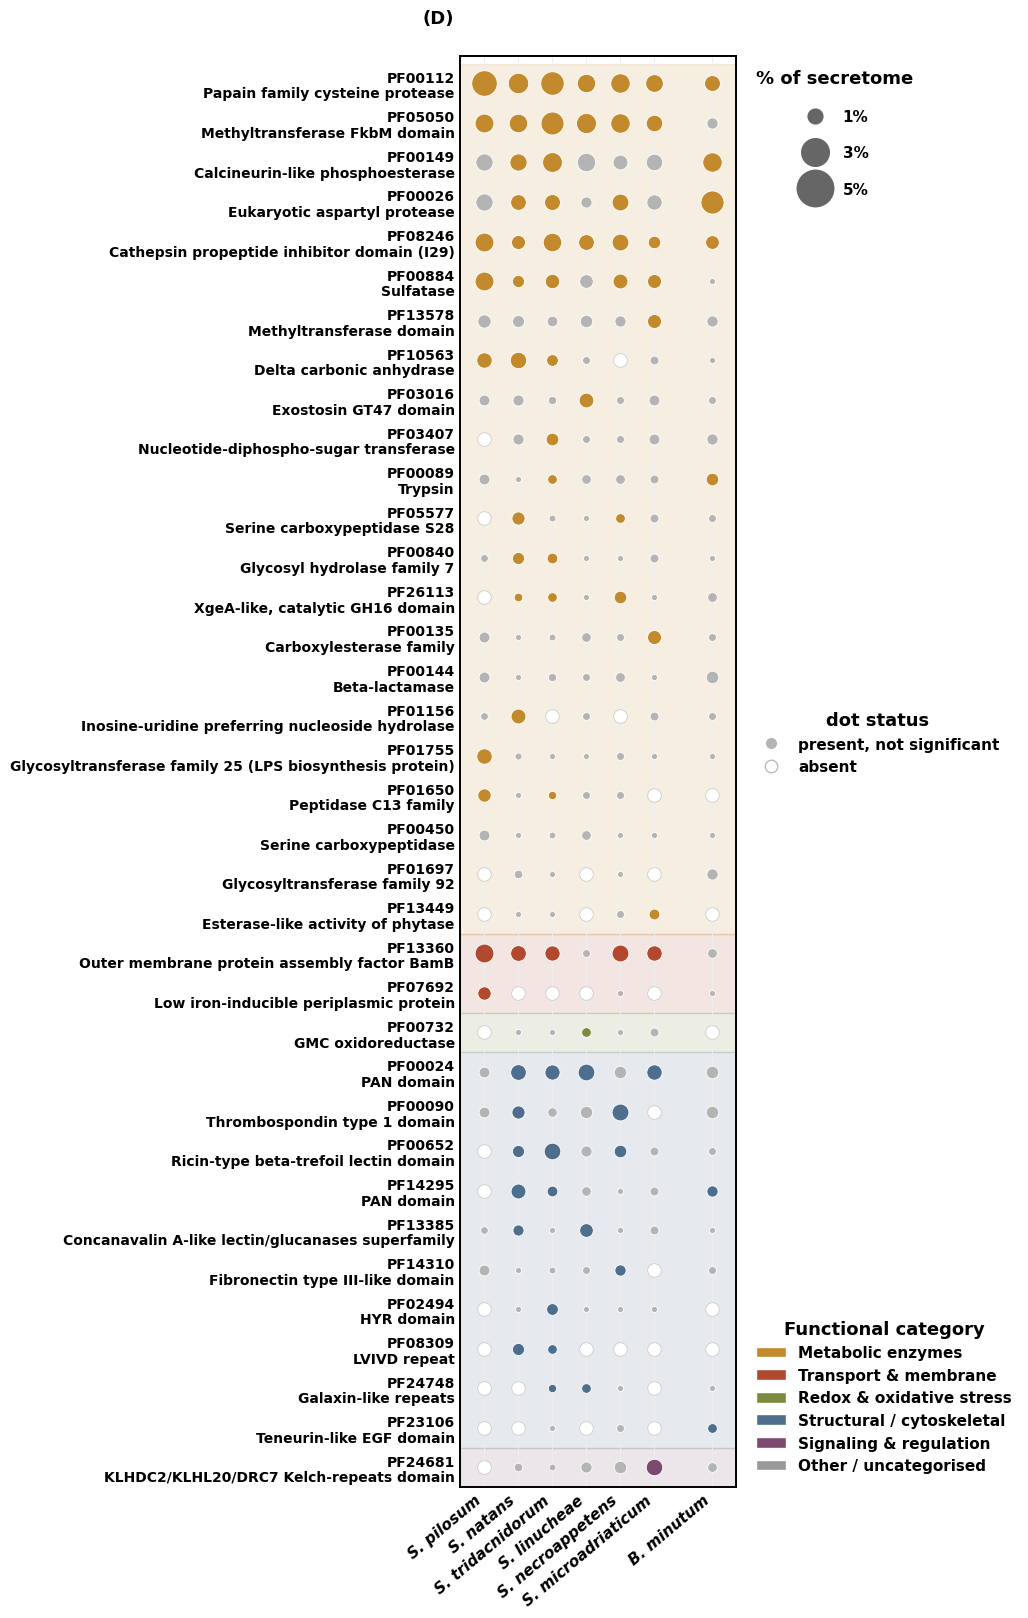

[CHECK] columns shown: 36 | left margin: 0.58
Saved bubble matrix to /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre


In [ ]:
# ============================================================
# MAIN FIGURE (draft): secretome-enriched Pfam bubble matrix
#   rows = 7 strains (phylo order, clade gap); NO tree (see Fig 5)
#   cols = union of top-5 per-strain-enriched Pfams, grouped into
#          6 functional categories (colored background bands)
#   dot SIZE  = % of that strain's secretome carrying the domain
#   dot COLOR = category color if per-strain significant;
#               grey if present-not-significant; absent = no dot
# ============================================================
import os, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
from collections import Counter

DATA_PRE = os.path.join(base, "Publication", "data_pre")
figdir   = os.path.join(base, "Publication", "figures_pre"); os.makedirs(figdir, exist_ok=True)

ORDER = ["Spil","Snat","Stri","Slin","Snec","Smic","Bmin"]
SYMB6 = ["Spil","Snat","Stri","Slin","Snec","Smic"]
RAW   = {s: ("Smic_jgi" if s=="Smic" else s) for s in ORDER}
SPP   = {"Spil":"S. pilosum","Snat":"S. natans","Stri":"S. tridacnidorum",
         "Slin":"S. linucheae","Snec":"S. necroappetens","Smic":"S. microadriaticum",
         "Bmin":"B. minutum"}
MIN_STRAIN_COUNT, FDR_SIG = 3, 0.05
TOP_PER_STRAIN = 10

# ── functional categories + colors ───────────────────────────────────
CATEGORY_ORDER = ["Metabolic enzymes","Transport & membrane","Redox & oxidative stress",
                  "Structural / cytoskeletal","Signaling & regulation","Other / uncategorised"]
CAT_COLOR = {"Metabolic enzymes":         "#C28A2D",
             "Transport & membrane":      "#B0492E",
             "Redox & oxidative stress":  "#7A8B3E",
             "Structural / cytoskeletal": "#4E6E8E",
             "Signaling & regulation":    "#7C4A6E",
             "Other / uncategorised":     "#999999"}
BAND_ALPHA = 0.14
GREY = "#B4B4B4"     # present, not significant

# category -> Pfam accessions (single source of truth)
PFAM_BY_CATEGORY = {
    "Metabolic enzymes": [
        "PF00112","PF05050","PF00149","PF00026","PF08246","PF00884","PF13578",
        "PF10563","PF03016","PF03407","PF00089","PF05577","PF00840","PF26113","PF00314",
        "PF00135","PF00144","PF01156","PF01755","PF01650","PF00450","PF01697","PF13449",
    ],
    "Transport & membrane":     ["PF13360","PF07692"],
    "Redox & oxidative stress": ["PF00732"],
    # Structural / cytoskeletal — incl. secreted lectin / adhesion / ECM (master scheme)
    "Structural / cytoskeletal": [
        "PF00024","PF14295","PF00090","PF00652","PF13385","PF14310",
        "PF02494","PF08309","PF24748","PF23106",
    ],
    "Signaling & regulation":   ["PF24681"],
}
PFAM_CATEGORY_OVERRIDE = {pf: cat for cat, pfs in PFAM_BY_CATEGORY.items() for pf in pfs}

# keyword fallback (only for domains NOT overridden above); first match wins
KEYWORD_TIERS = [
    # --- Redox & oxidative stress (test early; some carry enzyme-ish substrings) ---
    ("Redox & oxidative stress", [
        "oxidoreduct","peroxidas","thioredox","glutaredox","superoxide","dismutas",
        "catalase","tyrosinase","redox","2og-fe","2-og","oxygenase","dioxygenase",
        "erp29","erv1","alr family","sulfhydryl oxidase","creg","monooxygenase",
    ]),
    # --- Transport & membrane ---
    ("Transport & membrane", [
        "transport","permease","channel","porin","membrane","abc transporter",
        "secretion","periplasmic","bamb","fea1","vit","pbp superfamily",
        "nod 19","nod19","solute-binding",
    ]),
    # --- Structural / cytoskeletal (adhesion / ECM / lectin; per master scheme) ---
    ("Structural / cytoskeletal", [
        "actin","tubulin","collagen","fibronectin","laminin","cadherin","lectin",
        "ricin","thrombospondin","pan domain","cbm","egf","ferm",
        "cellulose binding","cellulose-binding","spondin","pa14","pa domain",
        "somatomedin","f5/8","f5_f8","calreticulin","mam domain","mam,","filamin",
        "abp280","cub domain","trefoil","wsc domain","furin-like","furin repeat",
        "leucine rich repeat","leucine-rich repeat","spore coat","concanavalin",
        "beta sandwich","beta-sandwich",
    ]),
    # --- Signaling & regulation ---
    ("Signaling & regulation", [
        "kinase","phosphatase","receptor","ubiquit","ef-hand","ankyrin","kelch",
        "f-box","srcr","notch","gtpase","signal","shk domain","sel1 repeat",
        "lipocalin","interleukin","emt inducer","chemotaxis","sh3","sh3bp",
    ]),
    # --- Metabolic enzymes (broad enzyme sweep; runs after the specific tiers) ---
    ("Metabolic enzymes", [
        "protease","peptidas","hydrolas","transferas","glycosyl","esteras","synthas",
        "lyase","ligase","isomeras","nuclease","sulfatase","carbonic","phytase",
        "trypsin","lactamase","reductas","lipase","amylase","fucosidase","galactosidase",
        "mannosidase","rhamnosidase","glucosidase","acetylglucosaminidase","naglu",
        "subtilase","subtilisin","convertase","expansin","expb","pullulanase",
        "dehydrogenase","nucleotidase","dehydratase","aldolase","dmf","dimethylformamidase",
        "dhh","cathepsin","perforin","mac/perforin","pngase","peptide-n-glycosidase",
        "tap-like","exclusion domain","glucanase","chitin","amidase","deaminase",
    ]),
    # --- Other / uncategorised (last; genuine dark matter) ---
    ("Other / uncategorised", ["duf","unknown","uncharacter","peridinin","glycine-rich",
        "counting factor","cog2071"]),
]
def auto_categorize(name):
    nm = ("" if not isinstance(name,str) else name).lower()
    for cat, kws in KEYWORD_TIERS:
        for kw in kws:
            if kw in nm: return cat, kw
    return "Other / uncategorised", "(no keyword)"

def categorize(acc, name):
    if acc in PFAM_CATEGORY_OVERRIDE: return PFAM_CATEGORY_OVERRIDE[acc], "override"
    return auto_categorize(name)

# ── load enriched pooled table + secretome sizes ─────────────────────
enr_path = next((p for p in [os.path.join(DATA_PRE,"enriched_pfam_by_strain.tsv"),
                             os.path.join(DATA_PRE,"SuppData_pfam_enriched_secretome.tsv")]
                 if os.path.exists(p)), None)
assert enr_path, "enriched Pfam table not found"
E = pd.read_csv(enr_path, sep="\t")
for s in ORDER: E[f"n_{s}"] = pd.to_numeric(E[f"n_{s}"], errors="coerce").fillna(0).astype(int)
NAME = dict(zip(E["pfam_domain"], E["pfam_name"]))

summ = pd.read_csv(os.path.join(DATA_PRE,"ALL_secretome_annotation_summary.tsv"), sep="\t")
Nsec = summ.groupby("strain")["n"].sum().to_dict()
assert all(s in Nsec for s in ORDER), "secretome sizes missing — check strain codes"

# ── whole-proteome Pfam + secreted sets (Block A), for per-strain test ─
if "whole_proteome_pfam_df" in globals(): W = whole_proteome_pfam_df.copy()
else: W = pd.read_csv(os.path.join(DATA_PRE,"ALL_whole_proteome_Pfam_final.tsv"), sep="\t")
W["Pfam_final"] = W["Pfam_final"].fillna("")

if "secreted_genes" in globals():
    sec_sets = secreted_genes
else:
    BMIN_RE = re.compile(r"(symbB\.v1\.2\.\d{6}\.t\d+)")
    def clean_protein_id(pid, strain):
        if not isinstance(pid,str): return pid
        pid=pid.strip()
        if strain=="Smic_jgi":
            if "|" in pid and "_" not in pid: h,t=pid.rsplit("|",1); return f"{h}_{t}"
            if "_" in pid:
                p=pid.split("_",3)
                if len(p)==4: return "|".join(p[:3])+"_"+p[3]
            return pid
        if strain=="Bmin":
            m=BMIN_RE.search(pid); return m.group(1) if m else pid.split("|")[0]
        return pid
    SR=os.path.join(base,"Prediction_vs_Detection")
    def fa(p):
        o=set()
        if os.path.exists(p):
            for l in open(p):
                if l.startswith(">"): o.add(l[1:].strip().split()[0])
        return o
    sec_sets={}
    for s in ORDER:
        r=RAW[s]
        sec_sets[r]={clean_protein_id(g,r) for g in
                     (fa(os.path.join(SR,r,"09_final",f"{r}_SP_pos_secretome_final.faa"))|
                      fa(os.path.join(SR,r,"09_final",f"{r}_SP_neg_secretome_final.faa")))}

sig = {}
for s in ORDER:
    r=RAW[s]; sub=W[W["strain"]==r]
    is_sec = sub["protein_id"].isin(sec_sets[r]).to_numpy()
    n_sec, n_bg = int(is_sec.sum()), int((~is_sec).sum())
    sc,bc = Counter(),Counter()
    for pf,sec in zip(sub["Pfam_final"].to_numpy(), is_sec):
        if pf:
            for d in set(pf.split(",")):
                if d: (sc if sec else bc)[d]+=1
    doms,ps,ors=[],[],[]
    for d in (set(sc)|set(bc)):
        a=sc.get(d,0); c=bc.get(d,0)
        if a+c<MIN_STRAIN_COUNT: continue
        orr,p=fisher_exact([[a,n_sec-a],[c,n_bg-c]],alternative="two-sided")
        doms.append(d); ps.append(p); ors.append(orr)
    fdr=multipletests(ps,method="fdr_bh")[1] if ps else []
    sig[s]={d:(f,o) for d,f,o in zip(doms,fdr,ors)}

def is_sig(s,d):
    f,o = sig[s].get(d,(np.nan,np.nan))
    return (not np.isnan(f)) and o>1 and f<FDR_SIG

# ── select top-5 per strain (from pooled-enriched set), union ────────
selected = set()
for s in ORDER:
    cand=[]
    for _,r in E.iterrows():
        d=r["pfam_domain"]; n=r[f"n_{s}"]
        if n==0: continue                       # absent from this strain's secretome
        pct=n/Nsec[s]*100
        f,o=sig[s].get(d,(1.0,np.nan))
        cand.append((d, 0 if is_sig(s,d) else 1, f if not np.isnan(f) else 1.0, -pct))
    cand.sort(key=lambda x:(x[1],x[2],x[3]))     # sig first, then FDR asc, then pct desc
    for d,_,_,_ in cand[:TOP_PER_STRAIN]: selected.add(d)
selected = [d for d in E["pfam_domain"] if d in selected]     # stable order
print(f"[CHECK] union of top-{TOP_PER_STRAIN}/strain: {len(selected)} domains")

# ── categorize + order columns by category ───────────────────────────
catmap = {d: categorize(d, NAME.get(d,"")) for d in selected}
review = pd.DataFrame({"pfam_domain":selected,
                       "pfam_name":[NAME.get(d,"") for d in selected],
                       "category":[catmap[d][0] for d in selected],
                       "matched_by":[catmap[d][1] for d in selected]})
ab = {d:int(E.loc[E["pfam_domain"]==d,"pooled_secreted_with"].iloc[0]) for d in selected}
review["pooled_secreted"] = [ab[d] for d in selected]
review["_c"]=pd.Categorical(review["category"],CATEGORY_ORDER,ordered=True)
review=review.sort_values(["_c","pooled_secreted"],ascending=[True,False]).drop(columns="_c")
print("\n=== CATEGORIZATION REVIEW (edit PFAM_CATEGORY_OVERRIDE as needed) ===")
print(review.to_string(index=False))
review.to_csv(os.path.join(DATA_PRE,"mainfig_pfam_categorization_review.tsv"),sep="\t",index=False)

cols = review["pfam_domain"].tolist()          # final column order

# ── geometry: y by category (Pfam rows, gaps), x by strain (clade gap) ─
CAT_GAP, CLADE_GAP = 0.0, 0.7
ypos, bands, y = {}, [], 0.0
for cat in CATEGORY_ORDER:
    dd = [d for d in cols if catmap[d][0] == cat]
    if not dd: continue
    y0 = y
    for d in dd: ypos[d] = y; y += 1
    bands.append((cat, y0-0.5, y-0.5)); y += CAT_GAP
YMAX = y - CAT_GAP
xpos, x = {}, 0.0
for s in ORDER:
    xpos[s] = x; x += 1 + (CLADE_GAP if s == "Smic" else 0)

def dot_size(pct): return max(pct, 0.12)*160      # area ~ % secretome

# ── plot ─────────────────────────────────────────────────────────────
plt.rcParams.update({"font.family":"DejaVu Sans","font.weight":"bold",
                     "axes.labelweight":"bold","pdf.fonttype":42, "font.size":13})
fig, ax = plt.subplots(figsize=(0.75*len(ORDER)+4.5, 0.42*len(cols)+3.0))

# horizontal category bands (rows)
for cat, y0, y1 in bands:
    ax.axhspan(y0, y1, color=CAT_COLOR[cat], alpha=BAND_ALPHA, zorder=0)

for s in ORDER:
    for d in cols:
        n = int(E.loc[E["pfam_domain"]==d, f"n_{s}"].iloc[0])
        if n == 0:
            ax.scatter(xpos[s], ypos[d], s=dot_size(0.6), facecolor="white",
                       edgecolor="#CCCCCC", linewidth=0.6, zorder=2)
            continue
        pct = n/Nsec[s]*100
        col = CAT_COLOR[catmap[d][0]] if is_sig(s, d) else GREY
        ax.scatter(xpos[s], ypos[d], s=dot_size(pct), color=col,
                   edgecolor="white", linewidth=0.6, zorder=3)

# y-axis: full Pfam names (left)
ax.set_yticks([ypos[d] for d in cols])
def ylab(d):
    return f"{d}\n{str(NAME.get(d,''))}"
ax.set_yticklabels([ylab(d) for d in cols], fontsize=10, fontweight="bold", linespacing=1.15)
ax.set_ylim(YMAX-0.5, -0.7)                      # top-down (first category on top)

# x-axis: strains (bottom)
ax.set_xticks([xpos[s] for s in ORDER])
ax.set_xticklabels([SPP[s] for s in ORDER], rotation=40, ha="right",
                   fontstyle="italic", fontweight="bold", fontsize=11)
ax.set_xlim(-0.7, max(xpos.values())+0.7)

for side in ("top","right","left","bottom"):
    ax.spines[side].set_visible(True)
    ax.spines[side].set_linewidth(1.4)
ax.tick_params(length=0)
ax.grid(axis="x", color="#EEEEEE", linewidth=0.7, zorder=0)

# legends: size (% secretome), status, category
size_leg = [Line2D([0],[0],marker="o",color="w",markerfacecolor="#666",markeredgecolor="white",
                    markersize=np.sqrt(dot_size(p)), label=f"{p}%") for p in [1,3,5]]
l1 = ax.legend(handles=size_leg, title="% of secretome", loc="upper left",
               bbox_to_anchor=(1.02,1.0), frameon=False, labelspacing=1.4, fontsize=11)
l1.get_title().set_fontweight("bold"); ax.add_artist(l1)
stat_leg = [Line2D([0],[0],marker="o",color="w",markerfacecolor=GREY,markeredgecolor="white",
                    markersize=9,label="present, not significant"),
            Line2D([0],[0],marker="o",color="w",markerfacecolor="white",markeredgecolor="#BBB",
                    markersize=9,label="absent")]
l2 = ax.legend(handles=stat_leg, title="dot status", loc="center left",
               bbox_to_anchor=(1.02,0.52), frameon=False, fontsize=11)
l2.get_title().set_fontweight("bold"); ax.add_artist(l2)
cat_leg = [Patch(facecolor=CAT_COLOR[c],edgecolor="white",label=c) for c in CATEGORY_ORDER]
l3 = ax.legend(handles=cat_leg, title="Functional category",
               loc="lower left", bbox_to_anchor=(1.02,0.0), frameon=False, fontsize=11)
l3.get_title().set_fontweight("bold")

ax.text(-0.02, 1.02, "(D)", transform=ax.transAxes,
        fontsize=13, fontweight="bold", ha="right", va="bottom")

# auto-size left margin to the longest Pfam name so nothing clips ------
fig.canvas.draw()
maxw = max((t.get_window_extent().width for t in ax.get_yticklabels()), default=0)
left_frac = min(0.62, 0.10 + maxw/fig.bbox.width + 0.02)
fig.subplots_adjust(left=left_frac, right=0.86, top=0.92, bottom=0.13)

for ext in ("png","svg","pdf"):
    fig.savefig(os.path.join(figdir,f"mainfig_enriched_pfam_bubble.{ext}"),
                dpi=600, bbox_inches="tight")
plt.show()
print(f"[CHECK] columns shown: {len(cols)} | left margin: {left_frac:.2f}")
print("Saved bubble matrix to", figdir)

[CHECK] domains shown (all enriched): 167


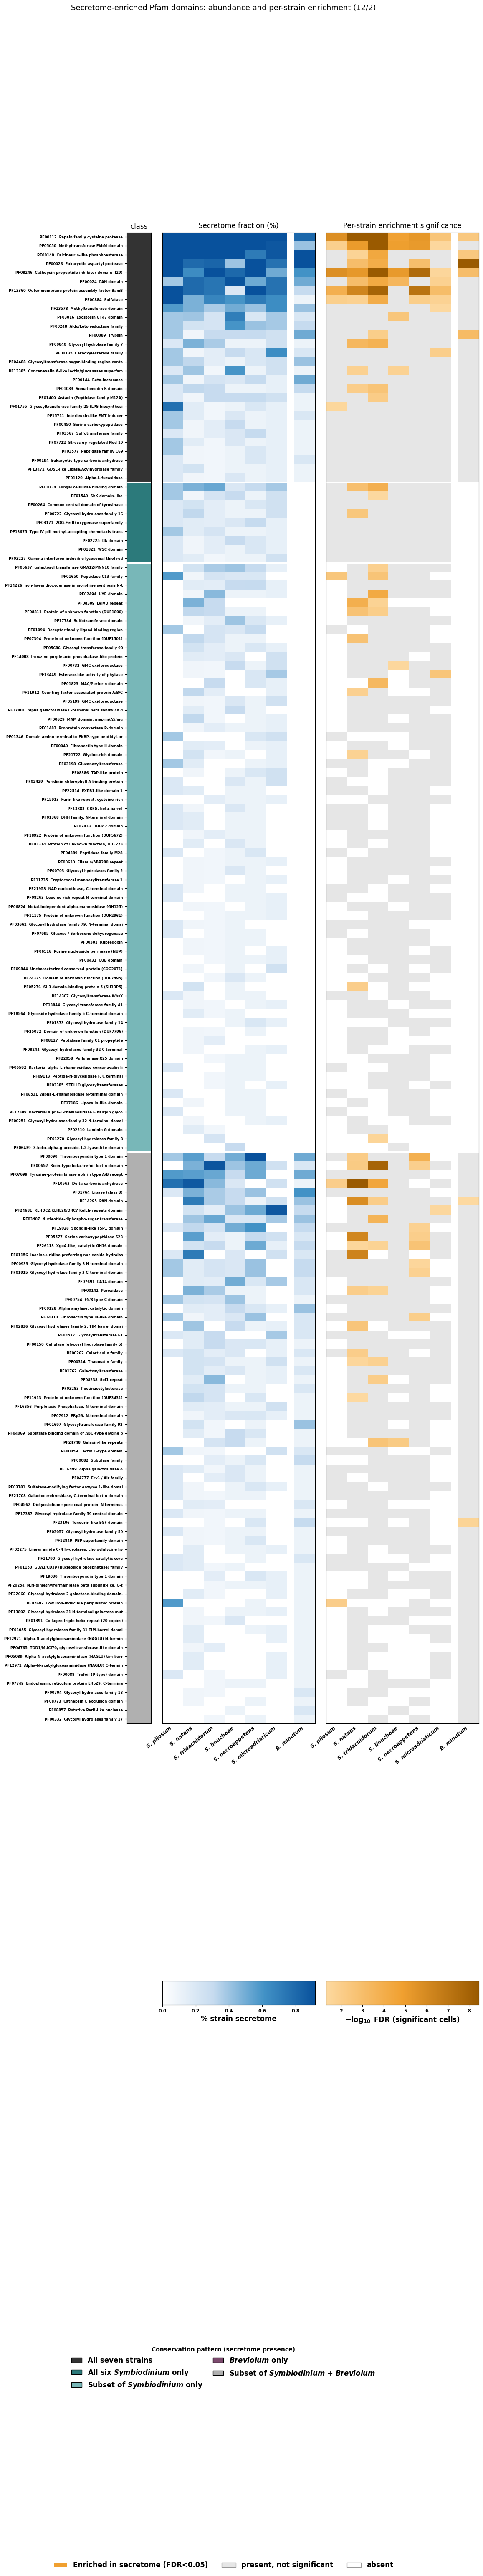

Saved to /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre


In [ ]:
# ============================================================
# Enriched Pfam: (A) secretome fraction  (B) per-strain enrichment
#   A = BLUE sequential (abundance) ; B = AMBER sequential (significance)
#   distinct color families (different quantities, different colors)
#   full Pfam names + wide label margin ; small controllable clade gap
# ============================================================
import os, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap, LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
from collections import Counter

DATA_PRE = os.path.join(base, "Publication", "data_pre")
figdir   = os.path.join(base, "Publication", "figures_pre"); os.makedirs(figdir, exist_ok=True)

ORDER = ["Spil","Snat","Stri","Slin","Snec","Smic","Bmin"]
SYMB6 = ["Spil","Snat","Stri","Slin","Snec","Smic"]
RAW   = {s: ("Smic_jgi" if s=="Smic" else s) for s in ORDER}
SPP   = {"Spil":"S. pilosum","Snat":"S. natans","Stri":"S. tridacnidorum",
         "Slin":"S. linucheae","Snec":"S. necroappetens","Smic":"S. microadriaticum",
         "Bmin":"B. minutum"}
MIN_STRAIN_COUNT, FDR_SIG = 3, 0.05
CLADE_GAP  = 0.35        # <-- clade gap width in column units (was a full 1.0 column)
NAME_TRUNC = 46          # Pfam name characters shown (raise if still clipped)

C_ALL7, C_SYM6 = "All seven strains", r"All six $\it{Symbiodinium}$ only"
C_SYMsub, C_BREV = r"Subset of $\it{Symbiodinium}$ only", r"$\it{Breviolum}$ only"
C_BOTH = r"Subset of $\it{Symbiodinium}$ + $\it{Breviolum}$"
CLASS_ORDER = [C_ALL7, C_SYM6, C_SYMsub, C_BREV, C_BOTH]
CLASS_COLOR = {C_ALL7:"#333333", C_SYM6:"#2C7A7B", C_SYMsub:"#78B7B8",
               C_BREV:"#7C4A6E", C_BOTH:"#B0B0B0"}

def classify_row(r):
    ns = sum(int(r[f"n_{s}"])>0 for s in SYMB6); br = int(r["n_Bmin"])>0
    if ns==6 and br: return C_ALL7
    if ns==6 and not br: return C_SYM6
    if 1<=ns<6 and not br: return C_SYMsub
    if br and ns==0: return C_BREV
    return C_BOTH

# ── load ALL enriched domains (supplementary: no top-K selection) ────
enr_path = next((p for p in [os.path.join(DATA_PRE,"enriched_pfam_by_strain.tsv"),
                             os.path.join(DATA_PRE,"SuppData_pfam_enriched_secretome.tsv")]
                 if os.path.exists(p)), None)
assert enr_path, "enriched Pfam table not found"
sel = pd.read_csv(enr_path, sep="\t")
for s in ORDER: sel[f"n_{s}"] = pd.to_numeric(sel[f"n_{s}"], errors="coerce").fillna(0).astype(int)
sel["spec_class"] = sel.apply(classify_row, axis=1)
sel = (sel.assign(_c=pd.Categorical(sel["spec_class"], CLASS_ORDER, ordered=True),
                  _ab=pd.to_numeric(sel["pooled_secreted_with"], errors="coerce").fillna(0))
          .sort_values(["_c","_ab"], ascending=[True,False]).reset_index(drop=True))
nrow = len(sel); print(f"[CHECK] domains shown (all enriched): {nrow}")

summ = pd.read_csv(os.path.join(DATA_PRE,"ALL_secretome_annotation_summary.tsv"), sep="\t")
Nsec = summ.groupby("strain")["n"].sum().to_dict()
assert all(s in Nsec for s in ORDER), "secretome sizes missing — check strain codes"

if "whole_proteome_pfam_df" in globals(): W = whole_proteome_pfam_df.copy()
else: W = pd.read_csv(os.path.join(DATA_PRE,"ALL_whole_proteome_Pfam_final.tsv"), sep="\t")
W["Pfam_final"] = W["Pfam_final"].fillna("")

if "secreted_genes" in globals():
    sec_sets = secreted_genes
else:
    BMIN_RE = re.compile(r"(symbB\.v1\.2\.\d{6}\.t\d+)")
    def clean_protein_id(pid, strain):
        if not isinstance(pid,str): return pid
        pid=pid.strip()
        if strain=="Smic_jgi":
            if "|" in pid and "_" not in pid: h,t=pid.rsplit("|",1); return f"{h}_{t}"
            if "_" in pid:
                p=pid.split("_",3)
                if len(p)==4: return "|".join(p[:3])+"_"+p[3]
            return pid
        if strain=="Bmin":
            m=BMIN_RE.search(pid); return m.group(1) if m else pid.split("|")[0]
        return pid
    SR=os.path.join(base,"Prediction_vs_Detection")
    def fa(p):
        o=set()
        if os.path.exists(p):
            for l in open(p):
                if l.startswith(">"): o.add(l[1:].strip().split()[0])
        return o
    sec_sets={}
    for s in ORDER:
        r=RAW[s]
        sec_sets[r]={clean_protein_id(g,r) for g in
                     (fa(os.path.join(SR,r,"09_final",f"{r}_SP_pos_secretome_final.faa"))|
                      fa(os.path.join(SR,r,"09_final",f"{r}_SP_neg_secretome_final.faa")))}

sig = {}
for s in ORDER:
    r=RAW[s]; sub=W[W["strain"]==r]
    is_sec = sub["protein_id"].isin(sec_sets[r]).to_numpy()
    n_sec, n_bg = int(is_sec.sum()), int((~is_sec).sum())
    sc, bc = Counter(), Counter()
    for pf, sec in zip(sub["Pfam_final"].to_numpy(), is_sec):
        if pf:
            for d in set(pf.split(",")):
                if d: (sc if sec else bc)[d]+=1
    doms, ps, ors = [], [], []
    for d in (set(sc)|set(bc)):
        a=sc.get(d,0); c=bc.get(d,0)
        if a+c < MIN_STRAIN_COUNT: continue
        orr,p = fisher_exact([[a,n_sec-a],[c,n_bg-c]], alternative="two-sided")
        doms.append(d); ps.append(p); ors.append(orr)
    fdr = multipletests(ps, method="fdr_bh")[1] if ps else []
    sig[s] = {d:(f,o) for d,f,o in zip(doms,fdr,ors)}

fr_mat  = np.vstack([ sel[f"n_{s}"].to_numpy()/Nsec[s]*100 for s in ORDER ]).T
present = fr_mat > 0
neglog  = np.full((nrow,len(ORDER)), np.nan); sigmask=np.zeros((nrow,len(ORDER)),bool)
for j,s in enumerate(ORDER):
    for i,d in enumerate(sel["pfam_domain"]):
        if d in sig[s]:
            f,o = sig[s][d]
            if o>1 and f<FDR_SIG: sigmask[i,j]=True; neglog[i,j]=-np.log10(max(f,1e-300))
cls_idx = np.array([CLASS_ORDER.index(c) for c in sel["spec_class"]])

# ── DISTINCT colormaps: A = blues, B = ambers ────────────────────────
plt.rcParams.update({"font.family":"DejaVu Sans","font.weight":"bold",
                     "axes.labelweight":"bold","pdf.fonttype":42})
frac_cmap = LinearSegmentedColormap.from_list("wblue",
              ["#FFFFFF","#C6DBEF","#4292C6","#08519C"]); frac_cmap.set_bad("white")
sig_cmap  = LinearSegmentedColormap.from_list("amber",
              ["#FDD9A0","#F0A030","#9A5A00"])
ABSENT, NOTSIG = "#FFFFFF", "#E6E6E6"

vmax = max(np.nanpercentile(neglog,95) if np.isfinite(neglog).any() else 3, -np.log10(FDR_SIG)+0.5)
norm = Normalize(vmin=-np.log10(FDR_SIG), vmax=vmax)
rgbaB = np.ones((nrow,len(ORDER),4))
for i in range(nrow):
    for j in range(len(ORDER)):
        if not present[i,j]:   rgbaB[i,j]=mcolors.to_rgba(ABSENT)
        elif not sigmask[i,j]: rgbaB[i,j]=mcolors.to_rgba(NOTSIG)
        else:                  rgbaB[i,j]=sig_cmap(norm(neglog[i,j]))

# split into Symbiodinium block (cols 0-5) and Breviolum col (6) -------
def blocks(M): return M[:, :6], M[:, 6:7]
frL, frR   = blocks(fr_mat)
rgL, rgR   = rgbaB[:, :6, :], rgbaB[:, 6:7, :]
Y = [nrow-0.5, -0.5]                          # extent y (origin upper)
GX = 6 + CLADE_GAP                            # left edge of Bmin block
xt = [0.5,1.5,2.5,3.5,4.5,5.5, GX+0.5]; xlabels=[SPP[s] for s in ORDER]

# ── layout: strip | A | B  (row 0) ; colorbars (row 1) ───────────────
ROW_H = 0.36                                   # inches per row (tighter for many rows)
LAB_FS = 8 if nrow <= 60 else (7 if nrow <= 120 else 6)   # row-label font scales down
fig = plt.figure(figsize=(13.6, ROW_H*nrow + 4.2))
gs  = fig.add_gridspec(2, 3, width_ratios=[0.16,1,1], height_ratios=[1,0.016],
                       wspace=0.10, hspace=0.34)
ax_s=fig.add_subplot(gs[0,0]); axA=fig.add_subplot(gs[0,1], sharey=ax_s)
axB =fig.add_subplot(gs[0,2], sharey=ax_s)
caxA=fig.add_subplot(gs[1,1]); caxB=fig.add_subplot(gs[1,2])

ax_s.imshow(cls_idx[:,None], aspect="auto",
            cmap=ListedColormap([CLASS_COLOR[c] for c in CLASS_ORDER]),
            vmin=0, vmax=len(CLASS_ORDER)-1)
ax_s.set_xticks([]); ax_s.set_yticks(range(nrow))
ax_s.set_yticklabels([f"{r['pfam_domain']}  {str(r['pfam_name'])[:NAME_TRUNC]}"
                      for _,r in sel.iterrows()], fontsize=LAB_FS, fontweight="bold")
ax_s.set_title("class", fontsize=12, pad=6)

vA = np.nanpercentile(fr_mat[fr_mat>0],97) if (fr_mat>0).any() else 1
imA = axA.imshow(frL, aspect="auto", cmap=frac_cmap, vmin=0, vmax=vA,
                 extent=[0,6,Y[0],Y[1]], origin="upper")
axA.imshow(frR, aspect="auto", cmap=frac_cmap, vmin=0, vmax=vA,
           extent=[GX,GX+1,Y[0],Y[1]], origin="upper")
axB.imshow(rgL, aspect="auto", extent=[0,6,Y[0],Y[1]], origin="upper")
axB.imshow(rgR, aspect="auto", extent=[GX,GX+1,Y[0],Y[1]], origin="upper")

for ax,ttl in [(axA,"Secretome fraction (%)"),(axB,"Per-strain enrichment significance")]:
    ax.set_xlim(0, GX+1); ax.set_xticks(xt)
    ax.set_xticklabels(xlabels, rotation=40, ha="right", fontstyle="italic", fontsize=9)
    ax.set_title(ttl, fontsize=12, pad=8)
    plt.setp(ax.get_yticklabels(), visible=False); ax.tick_params(length=0)
ax_s.set_ylim(nrow-0.5, -0.5)

bnd = np.where(np.diff(cls_idx)!=0)[0]+0.5
for ax in (ax_s,axA,axB):
    for b in bnd: ax.axhline(b, color="white", lw=2.2)

cbA = fig.colorbar(imA, cax=caxA, orientation="horizontal")
cbA.set_label("% strain secretome", fontsize=12); cbA.ax.tick_params(labelsize=8)
smB = ScalarMappable(norm=norm, cmap=sig_cmap); smB.set_array([])
cbB = fig.colorbar(smB, cax=caxB, orientation="horizontal")
cbB.set_label(r"$-\log_{10}$ FDR (significant cells)", fontsize=12); cbB.ax.tick_params(labelsize=8)

cls_h=[Patch(facecolor=CLASS_COLOR[c],edgecolor="black",label=c) for c in CLASS_ORDER]
st_h =[Patch(facecolor="#F0A030",edgecolor="white",label=f"Enriched in secretome (FDR<{FDR_SIG})"),
       Patch(facecolor=NOTSIG,edgecolor="#999999",label="present, not significant"),
       Patch(facecolor=ABSENT,edgecolor="#999999",label="absent")]
l1=fig.legend(handles=cls_h, loc="upper center", bbox_to_anchor=(0.5,0.115),
              ncol=2, frameon=False, fontsize=12,
              title="Conservation pattern (secretome presence)",
              columnspacing=1.5, handlelength=1.5); l1.get_title().set_fontweight("bold")
fig.legend(handles=st_h, loc="upper center", bbox_to_anchor=(0.5,0.035),
           ncol=3, frameon=False, fontsize=12)

fig.suptitle("Secretome-enriched Pfam domains: abundance and per-strain enrichment (12/2)",
             fontsize=13, y=0.985)
fig.subplots_adjust(left=0.33, right=0.95, top=0.90, bottom=0.24)

for ext in ("png","svg","pdf"):
    fig.savefig(os.path.join(figdir,f"enriched_pfam_significance_heatmap.{ext}"),
                dpi=600, bbox_inches="tight")
plt.show()
print("Saved to", figdir)

### Categories of secretome-enriched Pfams

In [ ]:
# ============================================================
# Categorize the FULL enriched-Pfam set (167) for Panel B
#   draft pass: apply override + keyword fallback, then REVIEW
#   -> shows how many land in each category and what's unresolved
# ============================================================
import os
import numpy as np, pandas as pd

DATA_PRE = os.path.join(base, "Publication", "data_pre")

CATEGORY_ORDER = ["Metabolic enzymes","Transport & membrane","Redox & oxidative stress",
                  "Structural / cytoskeletal","Signaling & regulation","Other / uncategorised"]

# reuse your existing PFAM_CATEGORY_OVERRIDE + KEYWORD_TIERS from the Panel C cell.
# (they must already be defined in this session; if not, re-run that block first.)
assert "PFAM_CATEGORY_OVERRIDE" in globals() and "KEYWORD_TIERS" in globals(), \
    "Run the Panel C categorization block first (defines override + keyword tiers)."

def auto_categorize(name):
    nm = ("" if not isinstance(name,str) else name).lower()
    for cat, kws in KEYWORD_TIERS:
        for kw in kws:
            if kw in nm: return cat, kw
    return "Other / uncategorised", "(no keyword)"
def categorize(acc, name):
    if acc in PFAM_CATEGORY_OVERRIDE: return PFAM_CATEGORY_OVERRIDE[acc], "override"
    return auto_categorize(name)

# ── full enriched table (all 167) ────────────────────────────────────
enr_path = next((p for p in [os.path.join(DATA_PRE,"enriched_pfam_by_strain.tsv"),
                             os.path.join(DATA_PRE,"SuppData_pfam_enriched_secretome.tsv")]
                 if os.path.exists(p)), None)
assert enr_path, "enriched table not found"
E = pd.read_csv(enr_path, sep="\t")
E["pooled_secreted_with"] = pd.to_numeric(E["pooled_secreted_with"], errors="coerce").fillna(0).astype(int)

rows=[]
for _,r in E.iterrows():
    cat,how = categorize(r["pfam_domain"], r["pfam_name"])
    rows.append({"pfam_domain":r["pfam_domain"],"pfam_name":r["pfam_name"],
                 "category":cat,"matched_by":how,"pooled_secreted":r["pooled_secreted_with"]})
full = pd.DataFrame(rows)
full["_c"]=pd.Categorical(full["category"],CATEGORY_ORDER,ordered=True)
full=full.sort_values(["_c","pooled_secreted"],ascending=[True,False]).drop(columns="_c")

# ── summary: how many per category, how many unresolved ──────────────
print("=== category totals (all enriched domains) ===")
print(full["category"].value_counts().reindex(CATEGORY_ORDER).fillna(0).astype(int).to_string())
n_override = (full["matched_by"]=="override").sum()
n_keyword  = full["matched_by"].isin(["(no keyword)"]).eq(False).sum() - n_override
n_nomatch  = (full["matched_by"]=="(no keyword)").sum()
print(f"\nassigned by override: {n_override} | by keyword: {n_keyword} | "
      f"fell through to Other (no keyword): {n_nomatch}")

# ── the domains that need your attention: went to 'Other' ────────────
other = full[full["category"]=="Other / uncategorised"].sort_values("pooled_secreted",ascending=False)
print(f"\n=== {len(other)} domains in 'Other / uncategorised' (add high-count ones to override) ===")
print(other[["pfam_domain","pfam_name","matched_by","pooled_secreted"]].to_string(index=False))

out=os.path.join(DATA_PRE,"enriched_pfam_full_categorization_review.tsv")
full.to_csv(out,sep="\t",index=False)
print(f"\n[SAVED] {out}")

=== category totals (all enriched domains) ===
category
Metabolic enzymes            93
Transport & membrane          6
Redox & oxidative stress     11
Structural / cytoskeletal    33
Signaling & regulation       12
Other / uncategorised        12

assigned by override: 37 | by keyword: 130 | fell through to Other (no keyword): 0

=== 12 domains in 'Other / uncategorised' (add high-count ones to override) ===
pfam_domain                                   pfam_name      matched_by  pooled_secreted
    PF08811       Protein of unknown function (DUF1800)             duf               10
    PF11913       Protein of unknown function (DUF3431)             duf               10
    PF07394       Protein of unknown function (DUF1501)             duf                9
    PF11912    Counting factor-associated protein A/B/C counting factor                7
    PF21722                         Glycine-rich domain    glycine-rich                6
    PF02429     Peridinin-chlorophyll A binding prote

[CHECK] enriched domains: 167 | in Other: 12
[CHECK] enriched secreted proteins per strain: {'Spil': 128, 'Snat': 338, 'Stri': 341, 'Slin': 240, 'Snec': 238, 'Smic': 165, 'Bmin': 183}


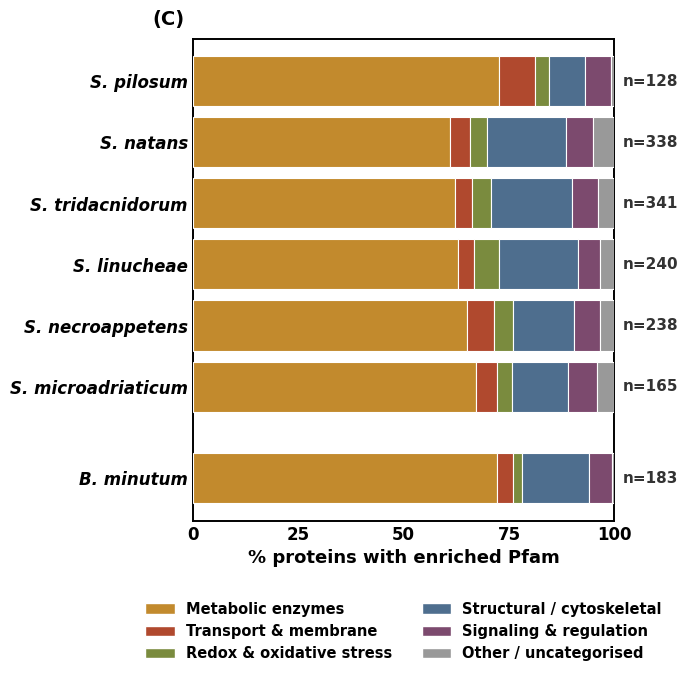

Saved Panel C to /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre


In [ ]:
# ============================================================
# PANEL C: functional category composition of the FULL enriched
#          secretome (all 167 enriched Pfams), per strain
#   horizontal 100% stacked bars; strains phylo order + clade gap
#   protein-weighted, single category per protein (priority = CATEGORY_ORDER)
#   colors identical to Panels A, B, D
# ============================================================
import os, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

DATA_PRE = os.path.join(base, "Publication", "data_pre")
figdir   = os.path.join(base, "Publication", "figures_pre"); os.makedirs(figdir, exist_ok=True)

ORDER = ["Spil","Snat","Stri","Slin","Snec","Smic","Bmin"]
RAW   = {s: ("Smic_jgi" if s=="Smic" else s) for s in ORDER}
SPP   = {"Spil":"S. pilosum","Snat":"S. natans","Stri":"S. tridacnidorum",
         "Slin":"S. linucheae","Snec":"S. necroappetens","Smic":"S. microadriaticum",
         "Bmin":"B. minutum"}
CATEGORY_ORDER = ["Metabolic enzymes","Transport & membrane","Redox & oxidative stress",
                  "Structural / cytoskeletal","Signaling & regulation","Other / uncategorised"]
CAT_COLOR = {"Metabolic enzymes":"#C28A2D","Transport & membrane":"#B0492E",
             "Redox & oxidative stress":"#7A8B3E","Structural / cytoskeletal":"#4E6E8E",
             "Signaling & regulation":"#7C4A6E","Other / uncategorised":"#999999"}

# ── full-167 category map (from the review you just finalized) ───────
full = pd.read_csv(os.path.join(DATA_PRE,"enriched_pfam_full_categorization_review.tsv"), sep="\t")
# apply the one override so it's reflected even if the file predates it
full.loc[full["pfam_domain"]=="PF00314","category"] = "Metabolic enzymes"
cat_of = dict(zip(full["pfam_domain"], full["category"]))
enriched_set = set(full["pfam_domain"])
print(f"[CHECK] enriched domains: {len(enriched_set)} | "
      f"in Other: {(full['category']=='Other / uncategorised').sum()}")

# ── whole-proteome Pfam + secreted sets (Block A) ────────────────────
if "whole_proteome_pfam_df" in globals(): W = whole_proteome_pfam_df.copy()
else: W = pd.read_csv(os.path.join(DATA_PRE,"ALL_whole_proteome_Pfam_final.tsv"), sep="\t")
W["Pfam_final"] = W["Pfam_final"].fillna("")

if "secreted_genes" in globals():
    sec_sets = secreted_genes
else:
    BMIN_RE = re.compile(r"(symbB\.v1\.2\.\d{6}\.t\d+)")
    def clean_protein_id(pid, strain):
        if not isinstance(pid,str): return pid
        pid=pid.strip()
        if strain=="Smic_jgi":
            if "|" in pid and "_" not in pid: h,t=pid.rsplit("|",1); return f"{h}_{t}"
            if "_" in pid:
                p=pid.split("_",3)
                if len(p)==4: return "|".join(p[:3])+"_"+p[3]
            return pid
        if strain=="Bmin":
            m=BMIN_RE.search(pid); return m.group(1) if m else pid.split("|")[0]
        return pid
    SR=os.path.join(base,"Prediction_vs_Detection")
    def fa(p):
        o=set()
        if os.path.exists(p):
            for l in open(p):
                if l.startswith(">"): o.add(l[1:].strip().split()[0])
        return o
    sec_sets={}
    for s in ORDER:
        r=RAW[s]
        sec_sets[r]={clean_protein_id(g,r) for g in
                     (fa(os.path.join(SR,r,"09_final",f"{r}_SP_pos_secretome_final.faa"))|
                      fa(os.path.join(SR,r,"09_final",f"{r}_SP_neg_secretome_final.faa")))}

# priority for single-category assignment (index in CATEGORY_ORDER) ---
PRIORITY = {c:i for i,c in enumerate(CATEGORY_ORDER)}

counts = {s:{c:0 for c in CATEGORY_ORDER} for s in ORDER}
n_prot = {s:0 for s in ORDER}
for s in ORDER:
    r=RAW[s]; sub=W[W["strain"]==r]
    for pid,pf in zip(sub["protein_id"], sub["Pfam_final"]):
        if pid not in sec_sets[r] or not isinstance(pf,str) or not pf: continue
        hit = set(pf.split(",")) & enriched_set
        if not hit: continue
        cats = {cat_of[d] for d in hit}
        primary = min(cats, key=lambda c: PRIORITY[c])   # highest-priority category
        counts[s][primary]+=1; n_prot[s]+=1
print("[CHECK] enriched secreted proteins per strain:", {s:n_prot[s] for s in ORDER})

M = np.array([[counts[s][c] for c in CATEGORY_ORDER] for s in ORDER], float)
row_tot = M.sum(axis=1, keepdims=True)
pct = np.divide(M, row_tot, out=np.zeros_like(M), where=row_tot>0)*100

# ── plot ─────────────────────────────────────────────────────────────
GAP, BARH = 0.5, 0.82          # wider bars (was 0.66)
ypos, y = [], 0.0
for s in ORDER:
    ypos.append(y); y += 1 + (GAP if s=="Smic" else 0)
ypos = np.array(ypos)

plt.rcParams.update({"font.family":"DejaVu Sans","font.weight":"bold",
                     "axes.labelweight":"bold","pdf.fonttype":42,"font.size":12})
fig, ax = plt.subplots(figsize=(6.8, 7.2))      # match Panel A width, taller

left = np.zeros(len(ORDER))
for j,c in enumerate(CATEGORY_ORDER):
    ax.barh(ypos, pct[:,j], BARH, left=left, color=CAT_COLOR[c],
            edgecolor="white", linewidth=0.8, zorder=3, label=c)
    left += pct[:,j]                            # (no in-bar % labels)

# per-strain protein count — OUTSIDE the right frame (axes-fraction x)
for i,s in enumerate(ORDER):
    ax.text(1.02, ypos[i], f"n={n_prot[s]}",
            transform=ax.get_yaxis_transform(),   # x in axes frac, y in data
            ha="left", va="center", fontsize=11, fontweight="bold", color="#333",
            clip_on=False)

ax.set_yticks(ypos)
ax.set_yticklabels([SPP[s] for s in ORDER], fontstyle="italic", fontweight="bold", fontsize=12)
ax.set_ylim(ypos.max()+0.7, ypos.min()-0.7)
ax.set_xlim(0, 100); ax.set_xticks([0,25,50,75,100])
ax.set_xlabel("% proteins with enriched Pfam", fontsize=13)

# full frame (upper + right included)
for side in ("top","right","left","bottom"):
    ax.spines[side].set_visible(True); ax.spines[side].set_linewidth(1.4)
ax.tick_params(length=0)

ax.legend(handles=[Patch(facecolor=CAT_COLOR[c],edgecolor="white",label=c) for c in CATEGORY_ORDER],
          loc="upper center", bbox_to_anchor=(0.5,-0.14), ncol=2, frameon=False, fontsize=10.5)
ax.text(-0.02, 1.02, "(C)", transform=ax.transAxes, fontsize=14, fontweight="bold",
        ha="right", va="bottom")
fig.subplots_adjust(left=0.24, right=0.86, top=0.93, bottom=0.26)

for ext in ("png","svg","pdf"):
    fig.savefig(os.path.join(figdir,f"mainfig_enriched_category_composition_full.{ext}"),
                dpi=600, bbox_inches="tight")
plt.show()
print("Saved Panel C to", figdir)

### PCA analysis

[CHECK] enriched domains (features): 167
[CHECK] PCA input: 7 strains × 167 variable domains (dropped 0 constant)
Explained variance (%): [28.  19.5 16.7 14.6]

Top |loadings| PC1:
  PF07692  Low iron-inducible periplasmic pro   +0.14
  PF08531  Alpha-L-rhamnosidase N-terminal do   +0.14
  PF17389  Bacterial alpha-L-rhamnosidase 6 h   +0.14
  PF05592  Bacterial alpha-L-rhamnosidase con   +0.14
  PF00314  Thaumatin family                     -0.13
  PF03577  Peptidase family C69                 +0.13

Top |loadings| PC2:
  PF02225  PA domain                            +0.16
  PF01400  Astacin (Peptidase family M12A)      +0.16
  PF17784  Sulfotransferase domain              +0.15
  PF04488  Glycosyltransferase sugar-binding    -0.15
  PF00431  CUB domain                           +0.15
  PF11175  Protein of unknown function (DUF29   +0.15


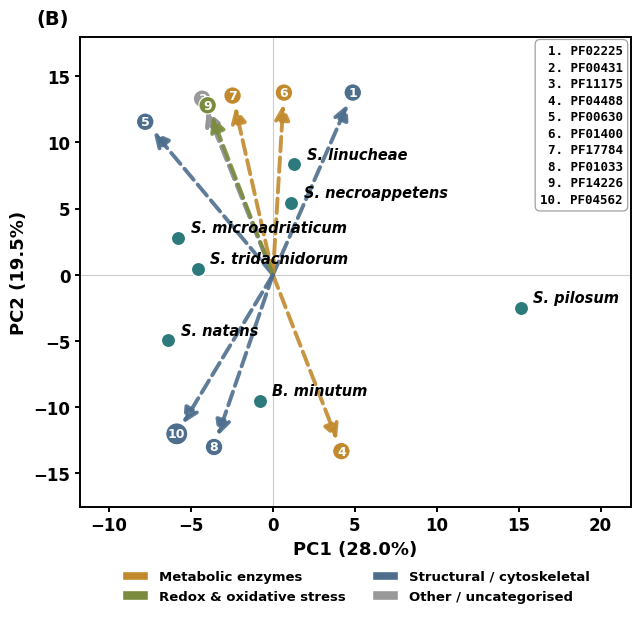

Saved Panel B to /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre


In [ ]:
# ============================================================
# PANEL B: PCA of strains in enriched-secretome space
#   obs = 7 strains ; features = 167 enriched Pfam domains
#   value = % of that strain's secretome carrying the domain
#   arrows = top-N domain loadings, numbered; key box top-right
# ============================================================
import os, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

DATA_PRE = os.path.join(base, "Publication", "data_pre")
figdir   = os.path.join(base, "Publication", "figures_pre"); os.makedirs(figdir, exist_ok=True)

ORDER = ["Spil","Snat","Stri","Slin","Snec","Smic","Bmin"]
RAW   = {s: ("Smic_jgi" if s=="Smic" else s) for s in ORDER}
SPP   = {"Spil":"S. pilosum","Snat":"S. natans","Stri":"S. tridacnidorum",
         "Slin":"S. linucheae","Snec":"S. necroappetens","Smic":"S. microadriaticum",
         "Bmin":"B. minutum"}
DOT_COLOR = "#2C7A7B"

# FIX: define category order + colors here (were only in Panel C/D)
CATEGORY_ORDER = ["Metabolic enzymes","Transport & membrane","Redox & oxidative stress",
                  "Structural / cytoskeletal","Signaling & regulation","Other / uncategorised"]
CAT_COLOR = {"Metabolic enzymes":"#C28A2D","Transport & membrane":"#B0492E",
             "Redox & oxidative stress":"#7A8B3E","Structural / cytoskeletal":"#4E6E8E",
             "Signaling & regulation":"#7C4A6E","Other / uncategorised":"#999999"}

# ── enriched domain set + names + category (full 167) ────────────────
full = pd.read_csv(os.path.join(DATA_PRE,"enriched_pfam_full_categorization_review.tsv"), sep="\t")
enriched = full["pfam_domain"].tolist()
NAME   = dict(zip(full["pfam_domain"], full["pfam_name"]))
cat_of = dict(zip(full["pfam_domain"], full["category"]))     # FIX: was undefined
enriched_set = set(enriched)
print(f"[CHECK] enriched domains (features): {len(enriched)}")

# ── secretome sizes + whole-proteome Pfam + secreted sets ────────────
summ = pd.read_csv(os.path.join(DATA_PRE,"ALL_secretome_annotation_summary.tsv"), sep="\t")
Nsec = summ.groupby("strain")["n"].sum().to_dict()

if "whole_proteome_pfam_df" in globals(): W = whole_proteome_pfam_df.copy()
else: W = pd.read_csv(os.path.join(DATA_PRE,"ALL_whole_proteome_Pfam_final.tsv"), sep="\t")
W["Pfam_final"] = W["Pfam_final"].fillna("")

if "secreted_genes" in globals():
    sec_sets = secreted_genes
else:
    BMIN_RE = re.compile(r"(symbB\.v1\.2\.\d{6}\.t\d+)")
    def clean_protein_id(pid, strain):
        if not isinstance(pid,str): return pid
        pid=pid.strip()
        if strain=="Smic_jgi":
            if "|" in pid and "_" not in pid: h,t=pid.rsplit("|",1); return f"{h}_{t}"
            if "_" in pid:
                p=pid.split("_",3)
                if len(p)==4: return "|".join(p[:3])+"_"+p[3]
            return pid
        if strain=="Bmin":
            m=BMIN_RE.search(pid); return m.group(1) if m else pid.split("|")[0]
        return pid
    SR=os.path.join(base,"Prediction_vs_Detection")
    def fa(p):
        o=set()
        if os.path.exists(p):
            for l in open(p):
                if l.startswith(">"): o.add(l[1:].strip().split()[0])
        return o
    sec_sets={}
    for s in ORDER:
        r=RAW[s]
        sec_sets[r]={clean_protein_id(g,r) for g in
                     (fa(os.path.join(SR,r,"09_final",f"{r}_SP_pos_secretome_final.faa"))|
                      fa(os.path.join(SR,r,"09_final",f"{r}_SP_neg_secretome_final.faa")))}

# ── strains × domains fraction matrix (% of secretome carrying domain) ─
from collections import Counter
frac = np.zeros((len(ORDER), len(enriched)))
didx = {d:i for i,d in enumerate(enriched)}
for si,s in enumerate(ORDER):
    r=RAW[s]; sub=W[W["strain"]==r]; cnt=Counter()
    for pid,pf in zip(sub["protein_id"], sub["Pfam_final"]):
        if pid in sec_sets[r] and isinstance(pf,str) and pf:
            for d in set(pf.split(","))&enriched_set: cnt[d]+=1
    for d,n in cnt.items(): frac[si, didx[d]] = n/Nsec[s]*100

F = pd.DataFrame(frac, index=ORDER, columns=enriched)
keep = F.columns[F.std(axis=0) > 0]
X = StandardScaler().fit_transform(F[keep].values)
print(f"[CHECK] PCA input: {X.shape[0]} strains × {X.shape[1]} variable domains "
      f"(dropped {len(enriched)-len(keep)} constant)")

pca = PCA(n_components=min(4, X.shape[0]-1))
scores = pca.fit_transform(X)
ev = pca.explained_variance_ratio_*100
print("Explained variance (%):", np.round(ev,1))

load = pd.DataFrame(pca.components_[:2].T, index=keep, columns=["PC1","PC2"])
for pc in ["PC1","PC2"]:
    top = load[pc].abs().sort_values(ascending=False).head(6).index
    print(f"\nTop |loadings| {pc}:")
    for d in top: print(f"  {d}  {str(NAME.get(d,''))[:34]:36s} {load.loc[d,pc]:+.2f}")

coords = pd.DataFrame(scores, index=ORDER, columns=[f"PC{i+1}" for i in range(scores.shape[1])])
coords.to_csv(os.path.join(DATA_PRE,"enriched_secretome_strain_PCA_coords.tsv"), sep="\t")

# ── FIG (FIX: create fig/ax before drawing) ──────────────────────────
plt.rcParams.update({"font.family":"DejaVu Sans","font.weight":"bold",
                     "axes.labelweight":"bold","pdf.fonttype":42,"font.size":12})
fig, ax = plt.subplots(figsize=(6.8, 6.8))
ax.axhline(0, color="#CCCCCC", lw=0.8, zorder=0)
ax.axvline(0, color="#CCCCCC", lw=0.8, zorder=0)

# ── arrows numbered 1..N ─────────────────────────────────────────────
N_ARROWS = 10
Lmag = np.hypot(load["PC1"].values, load["PC2"].values)
top_idx = np.argsort(Lmag)[::-1][:N_ARROWS]
top_doms = [keep[i] for i in top_idx]
Lsub = load.loc[top_doms, ["PC1","PC2"]].values
arr_scale = 0.85 * np.nanmax(np.abs(scores[:, :2])) / np.nanmax(np.abs(Lsub))
vec = Lsub * arr_scale

for k, d in enumerate(top_doms):
    col = CAT_COLOR[cat_of.get(d, "Other / uncategorised")]
    ax.annotate("", xy=(vec[k,0], vec[k,1]), xytext=(0,0),
                arrowprops=dict(arrowstyle="-|>", color=col, lw=2.8,
                                linestyle="--", shrinkA=0, shrinkB=0,
                                alpha=0.9, mutation_scale=22), zorder=2)
    ax.text(vec[k,0]*1.07, vec[k,1]*1.07, str(k+1), color="white", fontsize=9,
            fontweight="bold", ha="center", va="center", zorder=6,
            bbox=dict(boxstyle="circle,pad=0.18", fc=col, ec="white", lw=0.8))

# strain dots on top
for i,s in enumerate(ORDER):
    ax.scatter(scores[i,0], scores[i,1], s=110, color=DOT_COLOR,
               edgecolor="white", linewidth=1.2, zorder=5)
    ax.annotate(SPP[s], (scores[i,0], scores[i,1]), xytext=(9,4),
                textcoords="offset points", fontsize=10.5, fontstyle="italic",
                fontweight="bold", zorder=6)

ax.set_xlabel(f"PC1 ({ev[0]:.1f}%)", fontsize=13)
ax.set_ylabel(f"PC2 ({ev[1]:.1f}%)", fontsize=13)
for side in ("top","right","left","bottom"):
    ax.spines[side].set_visible(True); ax.spines[side].set_linewidth(1.4)
ax.tick_params(width=1.4)

# category legend (only categories present among the arrows)
handles = [Patch(facecolor=CAT_COLOR[c], edgecolor="white", label=c)
           for c in CATEGORY_ORDER if c in {cat_of.get(d) for d in top_doms}]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5,-0.11),
          ncol=2, frameon=False, fontsize=9.5)

# ── FIX: key box (number -> Pfam accession), top-right inside frame ──
key_text = "\n".join(f"{k+1}. {d}" for k, d in enumerate(top_doms))
ax.text(0.985, 0.985, key_text, transform=ax.transAxes, ha="right", va="top",
        fontsize=9, fontweight="bold", family="monospace", linespacing=1.35, zorder=7,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#999999", lw=0.9, alpha=0.92))

ax.text(-0.02, 1.02, "(B)", transform=ax.transAxes, fontsize=14, fontweight="bold",
        ha="right", va="bottom")

allx = np.concatenate([scores[:,0], vec[:,0]]); ally = np.concatenate([scores[:,1], vec[:,1]])
xr=np.ptp(allx) or 1; yr=np.ptp(ally) or 1
ax.set_xlim(allx.min()-0.20*xr, allx.max()+0.30*xr)
ax.set_ylim(ally.min()-0.20*yr, ally.max()+0.20*yr)
fig.subplots_adjust(left=0.14, right=0.95, top=0.93, bottom=0.24)

for ext in ("png","svg","pdf"):
    fig.savefig(os.path.join(figdir,f"mainfig_enriched_secretome_PCA.{ext}"),
                dpi=600, bbox_inches="tight")
plt.show()
print("Saved Panel B to", figdir)

[CHECK] variance PC1-3: [28.  19.5 16.7]  (cumulative 64.3%)


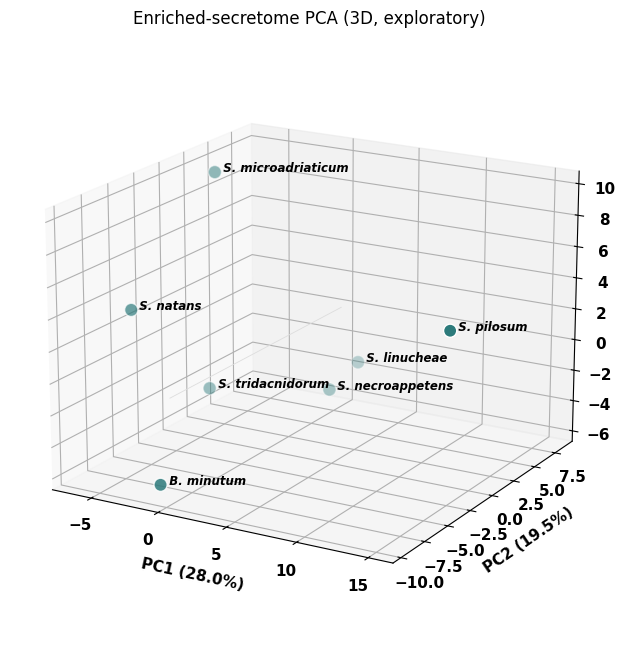

[SAVED] interactive HTML in figures_pre


In [ ]:
# ============================================================
# 3D PCA of strains in enriched-secretome space (exploratory)
#   reuses scores, ev, load, keep, ORDER, SPP from the PCA cell
#   version 1: static 3D (matplotlib) for paper/supplement
#   version 2: interactive 3D biplot (plotly) to rotate & read
# ============================================================
import os
import numpy as np
import matplotlib.pyplot as plt

DATA_PRE = os.path.join(base, "Publication", "data_pre")
figdir   = os.path.join(base, "Publication", "figures_pre")

assert "scores" in globals() and scores.shape[1] >= 3, \
    "Run the PCA cell first; need >=3 components (set n_components>=3)."

DOT_COLOR = "#2C7A7B"
ev3 = ev[:3]
print(f"[CHECK] variance PC1-3: {ev3.round(1)}  (cumulative {ev3.sum():.1f}%)")

# ── version 1: static 3D scatter (matplotlib) ────────────────────────
plt.rcParams.update({"font.family":"DejaVu Sans","font.weight":"bold",
                     "axes.labelweight":"bold","pdf.fonttype":42,"font.size":11})
fig = plt.figure(figsize=(7.2, 6.6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(scores[:,0], scores[:,1], scores[:,2], s=90, color=DOT_COLOR,
           edgecolor="white", linewidth=1.0, depthshade=True, zorder=3)
for i,s in enumerate(ORDER):
    ax.text(scores[i,0], scores[i,1], scores[i,2], f"  {SPP[s]}",
            fontsize=8.5, fontstyle="italic", fontweight="bold")

# faint origin planes
for a in (0,): ax.plot([a,a],[scores[:,1].min(),scores[:,1].max()],
                       [0,0], color="#DDD", lw=0.6, zorder=0)
ax.set_xlabel(f"PC1 ({ev3[0]:.1f}%)", fontsize=11, labelpad=6)
ax.set_ylabel(f"PC2 ({ev3[1]:.1f}%)", fontsize=11, labelpad=6)
ax.set_zlabel(f"PC3 ({ev3[2]:.1f}%)", fontsize=11, labelpad=6)
ax.view_init(elev=18, azim=-60)                 # viewing angle — rotate to taste
ax.set_title("Enriched-secretome PCA (3D, exploratory)", fontsize=12, pad=10)
fig.tight_layout()
for ext in ("png","svg","pdf"):
    fig.savefig(os.path.join(figdir,f"enriched_secretome_PCA_3D.{ext}"),
                dpi=600, bbox_inches="tight")
plt.show()

# ── version 2: interactive 3D biplot (plotly) ────────────────────────
try:
    import plotly.graph_objects as go
    N_ARROWS = 8
    Lmag = np.hypot.reduce([load["PC1"].values, load["PC2"].values]) if False else \
           np.sqrt(load["PC1"].values**2 + load["PC2"].values**2 + load["PC3"].values**2)
    top_idx = np.argsort(Lmag)[::-1][:N_ARROWS]
    top_doms = [keep[i] for i in top_idx]
    L = load.loc[top_doms, ["PC1","PC2","PC3"]].values
    scale = 0.85 * np.nanmax(np.abs(scores[:, :3])) / np.nanmax(np.abs(L))
    V = L * scale

    fig3 = go.Figure()
    # strain points
    fig3.add_trace(go.Scatter3d(
        x=scores[:,0], y=scores[:,1], z=scores[:,2],
        mode="markers+text", text=[SPP[s] for s in ORDER],
        textposition="top center", marker=dict(size=7, color=DOT_COLOR,
        line=dict(color="white", width=1)), name="strains"))
    # domain vectors
    for k,d in enumerate(top_doms):
        fig3.add_trace(go.Scatter3d(
            x=[0,V[k,0]], y=[0,V[k,1]], z=[0,V[k,2]], mode="lines+text",
            line=dict(color="#B0492E", width=4, dash="dash"),
            text=["", d], textposition="top center",
            textfont=dict(size=10), showlegend=False))
    fig3.update_layout(
        scene=dict(xaxis_title=f"PC1 ({ev3[0]:.1f}%)",
                   yaxis_title=f"PC2 ({ev3[1]:.1f}%)",
                   zaxis_title=f"PC3 ({ev3[2]:.1f}%)"),
        width=780, height=680, title="Enriched-secretome 3D biplot (drag to rotate)",
        margin=dict(l=0,r=0,t=40,b=0))
    fig3.show()
    fig3.write_html(os.path.join(figdir,"enriched_secretome_PCA_3D_interactive.html"))
    print("[SAVED] interactive HTML in figures_pre")
except ImportError:
    print("[note] plotly not installed — run: pip install plotly  (static 3D still saved)")

### Orthogroups containing enriched Pfam

[CHECK] enriched domains (rows): 36
[CHECK] qualifying orthogroups (≥1 secreted member carrying an enriched domain): 415


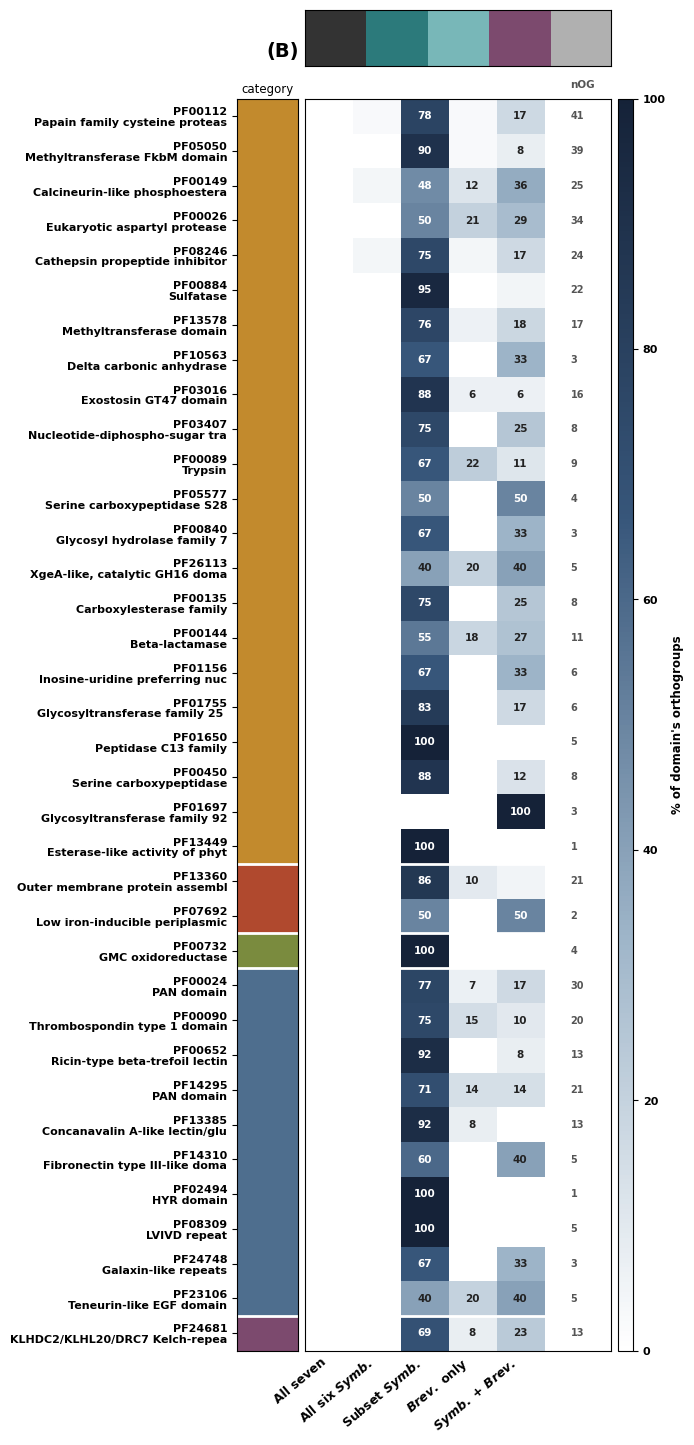

Saved Panel B to /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre


In [ ]:
# ============================================================
# PANEL B: orthogroup conservation of secretome-enriched Pfams
#   rows = enriched Pfam domains (same set/order as Panel C),
#          banded by functional category
#   cols = 5 secretome conservation classes (match Figure 5)
#   cell = row-normalized % of the domain's qualifying OGs in
#          each class (each row sums to 100%)
#   qualify = OG contains a SECRETED protein carrying the domain
#   class   = by strains contributing SECRETED members (Fig 5 logic)
# ============================================================
import os, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from collections import Counter

DATA_PRE = os.path.join(base, "Publication", "data_pre")
figdir   = os.path.join(base, "Publication", "figures_pre"); os.makedirs(figdir, exist_ok=True)
ORTHO    = os.path.join(base, "9_Ortholog_analysis", "Pro_OF_dendroblast", "Orthogroups")
OG_TSV   = os.path.join(ORTHO, "Orthogroups.tsv")
UN_TSV   = os.path.join(ORTHO, "Orthogroups_UnassignedGenes.tsv")

STRAINS_RAW = ["Spil","Snat","Stri","Slin","Snec","Smic_jgi","Bmin"]
SYM6_RAW    = STRAINS_RAW[:-1]

CATEGORY_ORDER = ["Metabolic enzymes","Transport & membrane","Redox & oxidative stress",
                  "Structural / cytoskeletal","Signaling & regulation","Other / uncategorised"]
CAT_COLOR = {"Metabolic enzymes":"#C28A2D","Transport & membrane":"#B0492E",
             "Redox & oxidative stress":"#7A8B3E","Structural / cytoskeletal":"#4E6E8E",
             "Signaling & regulation":"#7C4A6E","Other / uncategorised":"#999999"}

# 5 conservation classes — labels/colors matching Figure 5
C_ALL7  = "All seven"
C_SYM6  = r"All six $\it{Symb.}$"
C_SYMsub= r"Subset $\it{Symb.}$"
C_BREV  = r"$\it{Brev.}$ only"
C_BOTH  = r"$\it{Symb.}$ + $\it{Brev.}$"
CLASS_ORDER = [C_ALL7, C_SYM6, C_SYMsub, C_BREV, C_BOTH]
CLASS_COLOR = {C_ALL7:"#333333", C_SYM6:"#2C7A7B", C_SYMsub:"#78B7B8",
               C_BREV:"#7C4A6E", C_BOTH:"#B0B0B0"}

BMIN_RE = re.compile(r"(symbB\.v1\.2\.\d{6}\.t\d+)")
def clean_protein_id(pid, strain):
    if not isinstance(pid,str): return pid
    pid=pid.strip()
    if strain=="Smic_jgi":
        if "|" in pid and "_" not in pid: h,t=pid.rsplit("|",1); return f"{h}_{t}"
        if "_" in pid:
            p=pid.split("_",3)
            if len(p)==4: return "|".join(p[:3])+"_"+p[3]
        return pid
    if strain=="Bmin":
        m=BMIN_RE.search(pid); return m.group(1) if m else pid.split("|")[0]
    return pid

# ── rows: same domains/order/category as Panel C ─────────────────────
review = pd.read_csv(os.path.join(DATA_PRE,"mainfig_pfam_categorization_review.tsv"), sep="\t")
cols    = review["pfam_domain"].tolist()
cat_of  = dict(zip(review["pfam_domain"], review["category"]))
name_of = dict(zip(review["pfam_domain"], review["pfam_name"]))
enriched_set = set(cols)
print(f"[CHECK] enriched domains (rows): {len(cols)}")

# ── whole-proteome Pfam + secreted sets (Block A) ────────────────────
if "whole_proteome_pfam_df" in globals(): W = whole_proteome_pfam_df.copy()
else: W = pd.read_csv(os.path.join(DATA_PRE,"ALL_whole_proteome_Pfam_final.tsv"), sep="\t")
W["Pfam_final"] = W["Pfam_final"].fillna("")

if "secreted_genes" in globals():
    sec_sets = secreted_genes
else:
    SR=os.path.join(base,"Prediction_vs_Detection")
    def fa(p):
        o=set()
        if os.path.exists(p):
            for l in open(p):
                if l.startswith(">"): o.add(l[1:].strip().split()[0])
        return o
    sec_sets={}
    for s in STRAINS_RAW:
        sec_sets[s]={clean_protein_id(g,s) for g in
                     (fa(os.path.join(SR,s,"09_final",f"{s}_SP_pos_secretome_final.faa"))|
                      fa(os.path.join(SR,s,"09_final",f"{s}_SP_neg_secretome_final.faa")))}

# protein -> enriched domains it carries (secreted proteins only matter later)
dom_by_prot = {}
for st,pid,pf in zip(W["strain"],W["protein_id"],W["Pfam_final"]):
    if isinstance(pf,str) and pf:
        hit = set(pf.split(",")) & enriched_set
        if hit: dom_by_prot[(st,pid)] = hit

# ── classify OG by secreted-member presence (Fig 5 logic) ────────────
def og_class(present):
    sym_any = any(present[s] for s in SYM6_RAW)
    sym_all = all(present[s] for s in SYM6_RAW)
    bmin    = present["Bmin"]
    if sym_all and bmin:                       return C_ALL7
    if sym_all and not bmin:                   return C_SYM6
    if sym_any and not sym_all and not bmin:   return C_SYMsub
    if bmin and not sym_any:                   return C_BREV
    return C_BOTH

domain_class = {d: Counter() for d in cols}      # d -> class -> #OGs
def process(path):
    if not os.path.exists(path): print(f"[WARN] missing {path}"); return 0
    df = pd.read_csv(path, sep="\t", dtype=str)
    gcols = [c for c in df.columns if c in STRAINS_RAW]
    n=0
    for _,row in df.iterrows():
        present = {s:False for s in STRAINS_RAW}; dhits=set()
        for s in gcols:
            cell=row[s]
            if not isinstance(cell,str): continue
            for gid in cell.replace(", ",",").split(","):
                gid=gid.strip()
                if not gid: continue
                pid=clean_protein_id(gid,s)
                if pid in sec_sets[s]:
                    present[s]=True
                    d=dom_by_prot.get((s,pid))
                    if d: dhits|=d
        if not any(present.values()) or not dhits: continue
        cls=og_class(present)
        for d in dhits: domain_class[d][cls]+=1;
        n+=1
    return n
nq = process(OG_TSV) + process(UN_TSV)
print(f"[CHECK] qualifying orthogroups (≥1 secreted member carrying an enriched domain): {nq}")

# ── build % matrix + per-domain OG totals ────────────────────────────
M   = np.zeros((len(cols), 5)); nOG = np.zeros(len(cols), int)
for i,d in enumerate(cols):
    tot = sum(domain_class[d].values()); nOG[i]=tot
    if tot: M[i] = [domain_class[d][c]/tot*100 for c in CLASS_ORDER]
cat_idx = np.array([CATEGORY_ORDER.index(cat_of[d]) for d in cols])

# ── plot ─────────────────────────────────────────────────────────────
plt.rcParams.update({"font.family":"DejaVu Sans","font.weight":"bold",
                     "axes.labelweight":"bold","pdf.fonttype":42})
slate = LinearSegmentedColormap.from_list("slate", ["#FFFFFF","#9DB4C8","#37567A","#152238"])
nrow = len(cols)

fig = plt.figure(figsize=(6.6, 0.42*nrow+3.0))
gs  = fig.add_gridspec(2, 3, width_ratios=[0.20,1,0.05], height_ratios=[0.045,1],
                       wspace=0.05, hspace=0.05)
ax_top=fig.add_subplot(gs[0,1]); ax_s=fig.add_subplot(gs[1,0])
ax=fig.add_subplot(gs[1,1], sharey=ax_s); cax=fig.add_subplot(gs[1,2])

# category strip + row labels
ax_s.imshow(cat_idx[:,None], aspect="auto",
            cmap=ListedColormap([CAT_COLOR[c] for c in CATEGORY_ORDER]),
            vmin=0, vmax=len(CATEGORY_ORDER)-1)
ax_s.set_xticks([]); ax_s.set_yticks(range(nrow))
ax_s.set_yticklabels([f"{d}\n{str(name_of[d])[:30]}" for d in cols],
                     fontsize=8, fontweight="bold", linespacing=1.1)
ax_s.set_title("category", fontsize=8.5, pad=4)

# main heatmap
im = ax.imshow(M, aspect="auto", cmap=slate, vmin=0, vmax=100)
ax.set_xticks(range(5)); ax.set_xticklabels(CLASS_ORDER, rotation=40, ha="right", fontsize=9)
plt.setp(ax.get_yticklabels(), visible=False); ax.tick_params(length=0)
for i in range(nrow):
    for j in range(5):
        v=M[i,j]
        if v>=6:
            ax.text(j,i,f"{v:.0f}", ha="center", va="center", fontsize=7.5,
                    fontweight="bold", color="white" if v>=45 else "#222")
# per-domain OG count at right
for i in range(nrow):
    ax.text(5.05, i, f"{nOG[i]}", ha="left", va="center", fontsize=7, color="#555")
ax.text(5.05, -0.9, "nOG", ha="left", va="center", fontsize=7.5, fontweight="bold", color="#555")
ax.set_xlim(-0.5, 5.9)

# class-color header strip
ax_top.imshow(np.arange(5)[None,:], aspect="auto",
              cmap=ListedColormap([CLASS_COLOR[c] for c in CLASS_ORDER]), vmin=0, vmax=4)
ax_top.set_xticks([]); ax_top.set_yticks([])
ax_top.set_xlim(-0.5,4.5)

# category separators
for b in np.where(np.diff(cat_idx)!=0)[0]+0.5:
    ax_s.axhline(b, color="white", lw=2); ax.axhline(b, color="white", lw=2)

cb=fig.colorbar(im, cax=cax); cb.set_label("% of domain's orthogroups", fontsize=8.5)
cb.ax.tick_params(labelsize=8)

ax.text(-0.02, 1.03, "(B)", transform=ax.transAxes, fontsize=14, fontweight="bold",
        ha="right", va="bottom")
fig.subplots_adjust(left=0.30, right=0.90, top=0.90, bottom=0.16)

for ext in ("png","svg","pdf"):
    fig.savefig(os.path.join(figdir,f"mainfig_pfam_orthogroup_conservation.{ext}"),
                dpi=600, bbox_inches="tight")
plt.show()
print("Saved Panel B to", figdir)

In [ ]:
d = "PF24681"
for s in ORDER:
    f, o = sig[s].get(d, (float("nan"), float("nan")))
    star = "*" if (o>1 and f<0.05) else " "
    print(f"{s:5s} FDR={f:.2e} OR={o:6.2f} {star}")

Spil  FDR=1.00e+00 OR=  0.00  
Snat  FDR=1.00e+00 OR=  0.84  
Stri  FDR=1.00e+00 OR=  0.77  
Slin  FDR=1.00e+00 OR=  2.60  
Snec  FDR=3.10e-01 OR=  4.54  
Smic  FDR=4.01e-02 OR=  5.96 *
Bmin  FDR=1.00e+00 OR=  1.93  


## Combined figure

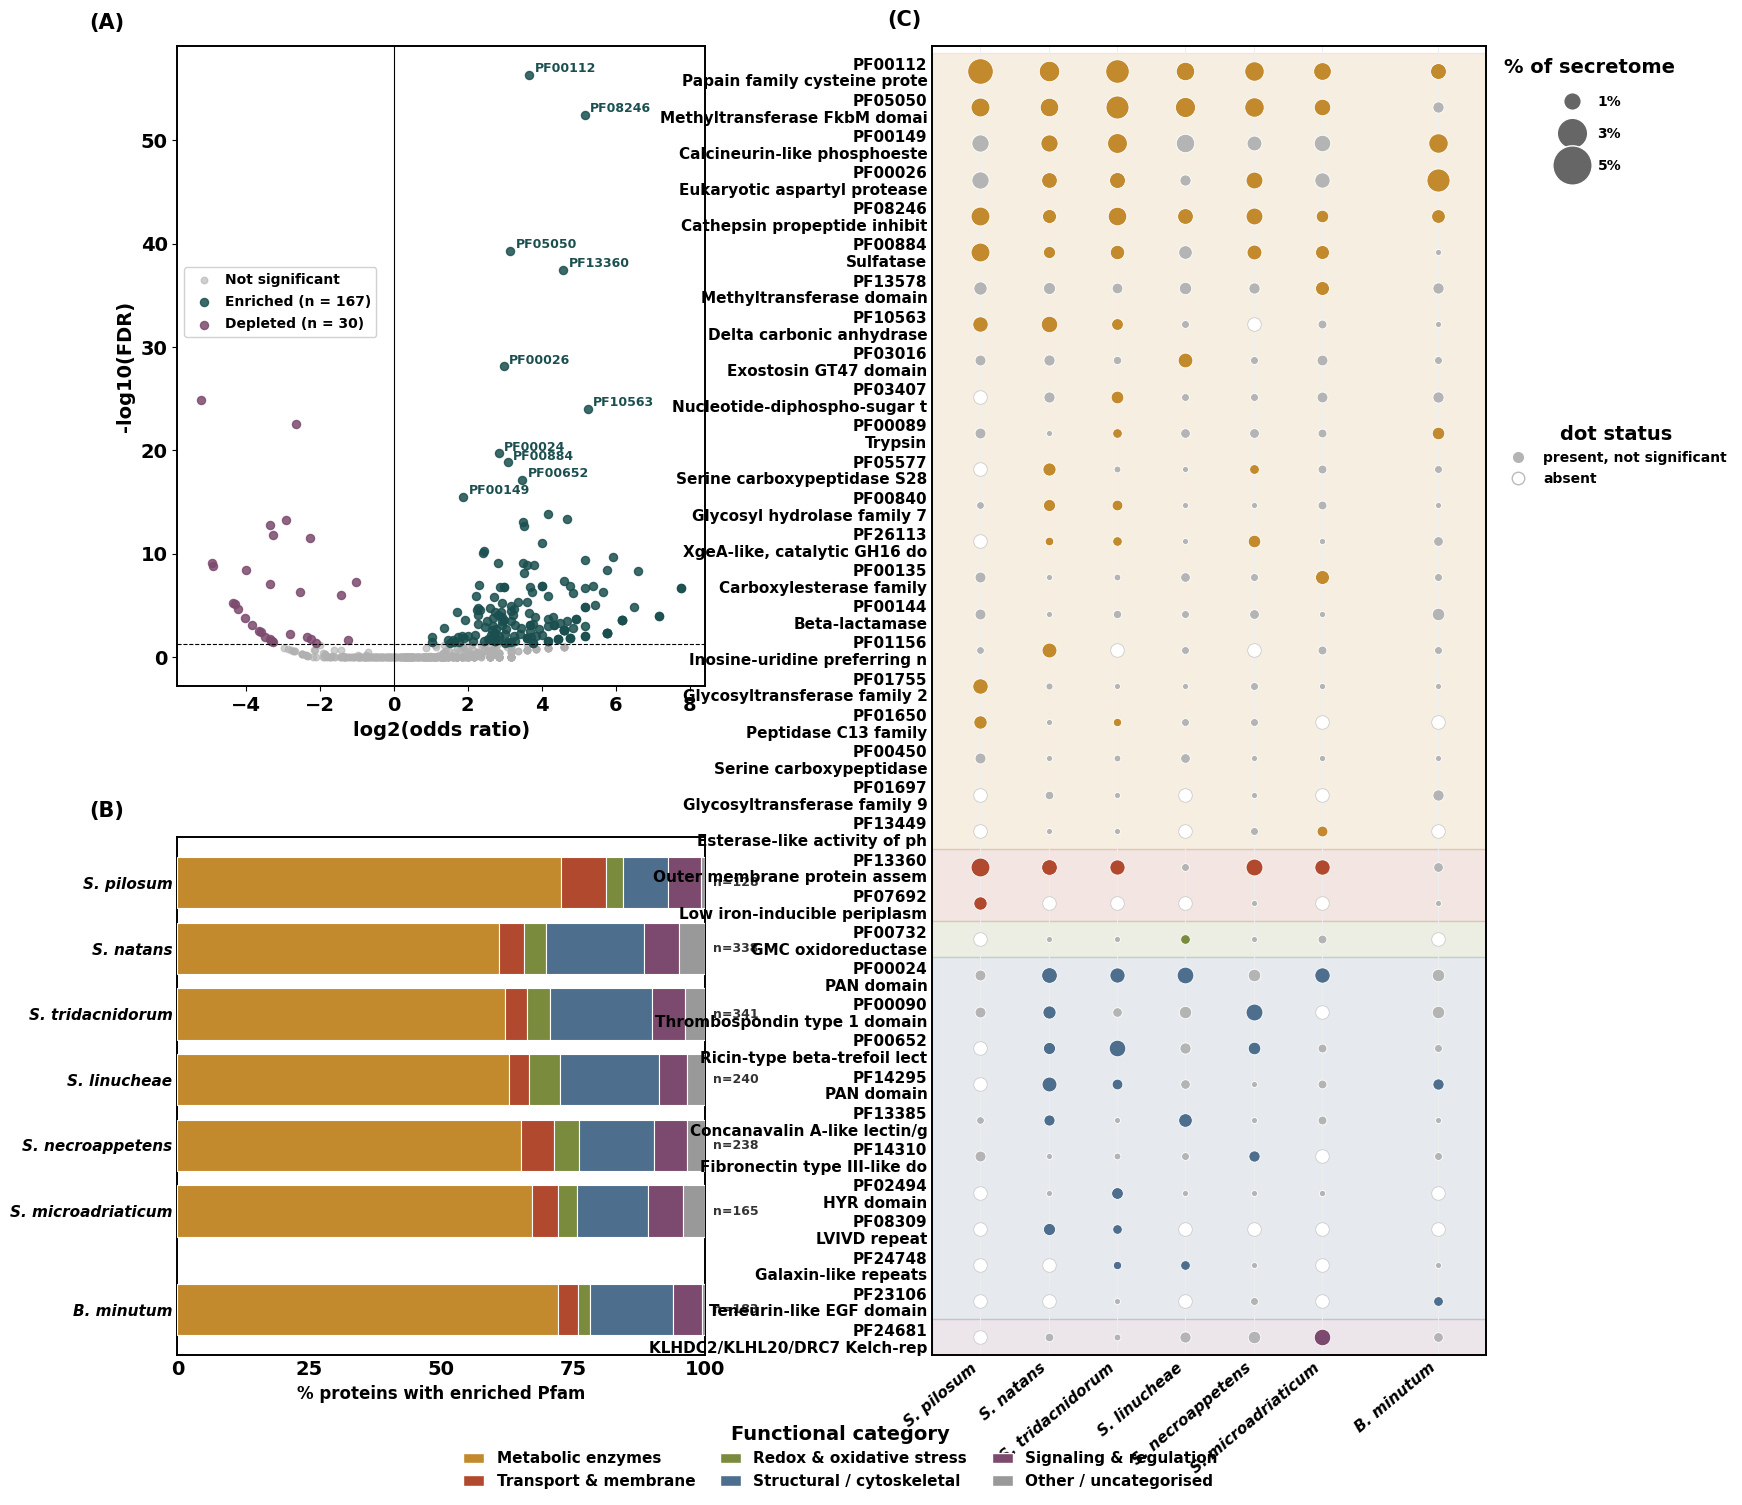

[CHECK] C rows: 36 | fig height: 15.5
Saved combined figure to /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre


In [3]:
# ============================================================
# COMBINED FIGURE: (A) volcano [top-left], (B) category bars
# [bottom-left], (C) enriched-Pfam bubble matrix [right, full height]
# ============================================================
import os, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
from collections import Counter

DATA_PRE = os.path.join(base, "Publication", "data_pre")
figdir   = os.path.join(base, "Publication", "figures_pre"); os.makedirs(figdir, exist_ok=True)

ORDER = ["Spil","Snat","Stri","Slin","Snec","Smic","Bmin"]
RAW   = {s: ("Smic_jgi" if s=="Smic" else s) for s in ORDER}
SPP   = {"Spil":"S. pilosum","Snat":"S. natans","Stri":"S. tridacnidorum",
         "Slin":"S. linucheae","Snec":"S. necroappetens","Smic":"S. microadriaticum",
         "Bmin":"B. minutum"}
MIN_STRAIN_COUNT, FDR_SIG, TOP_PER_STRAIN = 3, 0.05, 10
NAME_TRUNC = 28           # C name-line truncation in the combined layout

CATEGORY_ORDER = ["Metabolic enzymes","Transport & membrane","Redox & oxidative stress",
                  "Structural / cytoskeletal","Signaling & regulation","Other / uncategorised"]
CAT_COLOR = {"Metabolic enzymes":"#C28A2D","Transport & membrane":"#B0492E",
             "Redox & oxidative stress":"#7A8B3E","Structural / cytoskeletal":"#4E6E8E",
             "Signaling & regulation":"#7C4A6E","Other / uncategorised":"#999999"}
BAND_ALPHA, GREY = 0.14, "#B4B4B4"
VOL_UP, VOL_DOWN, VOL_NS = "#1B4F4F", "#7C4A6E", "#B0B0B0"

# ── categorization (override + keyword fallback) ─────────────────────
PFAM_BY_CATEGORY = {
    "Metabolic enzymes": ["PF00112","PF05050","PF00149","PF00026","PF08246","PF00884",
        "PF13578","PF10563","PF03016","PF03407","PF00089","PF05577","PF00840","PF26113",
        "PF00314","PF00135","PF00144","PF01156","PF01755","PF01650","PF00450","PF01697","PF13449"],
    "Transport & membrane":     ["PF13360","PF07692"],
    "Redox & oxidative stress": ["PF00732"],
    "Structural / cytoskeletal":["PF00024","PF14295","PF00090","PF00652","PF13385","PF14310",
        "PF02494","PF08309","PF24748","PF23106"],
    "Signaling & regulation":   ["PF24681"],
}
PFAM_CATEGORY_OVERRIDE = {pf: c for c, pfs in PFAM_BY_CATEGORY.items() for pf in pfs}
KEYWORD_TIERS = [
    ("Redox & oxidative stress", ["oxidoreduct","peroxidas","thioredox","glutaredox","superoxide",
        "dismutas","catalase","tyrosinase","redox","oxygenase","dioxygenase","erp29","erv1","creg"]),
    ("Transport & membrane", ["transport","permease","channel","porin","membrane","abc transporter",
        "secretion","periplasmic","bamb","fea1","vit","pbp superfamily","nod 19"]),
    ("Structural / cytoskeletal", ["actin","tubulin","collagen","fibronectin","laminin","cadherin",
        "lectin","ricin","thrombospondin","pan domain","cbm","egf","ferm","cellulose binding",
        "spondin","pa14","pa domain","somatomedin","f5/8","calreticulin","mam domain","filamin",
        "cub domain","trefoil","wsc domain","furin","leucine rich repeat","spore coat","concanavalin"]),
    ("Signaling & regulation", ["kinase","phosphatase","receptor","ubiquit","ef-hand","ankyrin",
        "kelch","f-box","srcr","notch","gtpase","signal","shk domain","sel1 repeat","lipocalin",
        "interleukin","chemotaxis","sh3"]),
    ("Metabolic enzymes", ["protease","peptidas","hydrolas","transferas","glycosyl","esteras","synthas",
        "lyase","ligase","isomeras","nuclease","sulfatase","carbonic","phytase","trypsin","lactamase",
        "reductas","lipase","amylase","fucosidase","galactosidase","mannosidase","rhamnosidase",
        "glucosidase","naglu","subtilase","convertase","expansin","expb","pullulanase","dehydrogenase",
        "nucleotidase","dhh","cathepsin","perforin","pngase","tap-like","glucanase","chitin"]),
    ("Other / uncategorised", ["duf","unknown","uncharacter","peridinin","glycine-rich",
        "counting factor","cog2071"]),
]
def auto_categorize(name):
    nm = ("" if not isinstance(name,str) else name).lower()
    for cat, kws in KEYWORD_TIERS:
        for kw in kws:
            if kw in nm: return cat
    return "Other / uncategorised"
def categorize(acc, name):
    return PFAM_CATEGORY_OVERRIDE.get(acc) or auto_categorize(name)

# ── shared data ──────────────────────────────────────────────────────
results_df = pd.read_csv(os.path.join(DATA_PRE,"pfam_enrichment_secretome_vs_background.tsv"), sep="\t")
E = pd.read_csv(os.path.join(DATA_PRE,"enriched_pfam_by_strain.tsv"), sep="\t")
for s in ORDER: E[f"n_{s}"] = pd.to_numeric(E[f"n_{s}"], errors="coerce").fillna(0).astype(int)
NAME = dict(zip(E["pfam_domain"], E["pfam_name"]))
summ = pd.read_csv(os.path.join(DATA_PRE,"ALL_secretome_annotation_summary.tsv"), sep="\t")
Nsec = summ.groupby("strain")["n"].sum().to_dict()
full = pd.read_csv(os.path.join(DATA_PRE,"enriched_pfam_full_categorization_review.tsv"), sep="\t")
full.loc[full["pfam_domain"]=="PF00314","category"] = "Metabolic enzymes"
cat_full = dict(zip(full["pfam_domain"], full["category"]))
enriched_full = set(full["pfam_domain"])

if "whole_proteome_pfam_df" in globals(): W = whole_proteome_pfam_df.copy()
else: W = pd.read_csv(os.path.join(DATA_PRE,"ALL_whole_proteome_Pfam_final.tsv"), sep="\t")
W["Pfam_final"] = W["Pfam_final"].fillna("")

if "secreted_genes" in globals():
    sec_sets = secreted_genes
else:
    BMIN_RE = re.compile(r"(symbB\.v1\.2\.\d{6}\.t\d+)")
    def clean_protein_id(pid, strain):
        if not isinstance(pid,str): return pid
        pid=pid.strip()
        if strain=="Smic_jgi":
            if "|" in pid and "_" not in pid: h,t=pid.rsplit("|",1); return f"{h}_{t}"
            if "_" in pid:
                p=pid.split("_",3)
                if len(p)==4: return "|".join(p[:3])+"_"+p[3]
            return pid
        if strain=="Bmin":
            m=BMIN_RE.search(pid); return m.group(1) if m else pid.split("|")[0]
        return pid
    SR=os.path.join(base,"Prediction_vs_Detection")
    def fa(p):
        o=set()
        if os.path.exists(p):
            for l in open(p):
                if l.startswith(">"): o.add(l[1:].strip().split()[0])
        return o
    sec_sets={}
    for s in ORDER:
        r=RAW[s]
        sec_sets[r]={clean_protein_id(g,r) for g in
                     (fa(os.path.join(SR,r,"09_final",f"{r}_SP_pos_secretome_final.faa"))|
                      fa(os.path.join(SR,r,"09_final",f"{r}_SP_neg_secretome_final.faa")))}

# per-strain enrichment (for C significance)
sig = {}
for s in ORDER:
    r=RAW[s]; sub=W[W["strain"]==r]
    is_sec = sub["protein_id"].isin(sec_sets[r]).to_numpy()
    n_sec, n_bg = int(is_sec.sum()), int((~is_sec).sum())
    sc,bc = Counter(),Counter()
    for pf,sec in zip(sub["Pfam_final"].to_numpy(), is_sec):
        if pf:
            for d in set(pf.split(",")):
                if d: (sc if sec else bc)[d]+=1
    doms,ps,ors=[],[],[]
    for d in (set(sc)|set(bc)):
        a=sc.get(d,0); c=bc.get(d,0)
        if a+c<MIN_STRAIN_COUNT: continue
        orr,p=fisher_exact([[a,n_sec-a],[c,n_bg-c]],alternative="two-sided")
        doms.append(d); ps.append(p); ors.append(orr)
    fdr=multipletests(ps,method="fdr_bh")[1] if ps else []
    sig[s]={d:(f,o) for d,f,o in zip(doms,fdr,ors)}
def is_sig(s,d):
    f,o = sig[s].get(d,(np.nan,np.nan))
    return (not np.isnan(f)) and o>1 and f<FDR_SIG

# C selection: top-10 per strain, union
selected=set()
for s in ORDER:
    cand=[]
    for _,r in E.iterrows():
        d=r["pfam_domain"]; n=r[f"n_{s}"]
        if n==0: continue
        pct=n/Nsec[s]*100
        f,o=sig[s].get(d,(1.0,np.nan))
        cand.append((d,0 if is_sig(s,d) else 1, f if not np.isnan(f) else 1.0, -pct))
    cand.sort(key=lambda x:(x[1],x[2],x[3]))
    for d,_,_,_ in cand[:TOP_PER_STRAIN]: selected.add(d)
selected=[d for d in E["pfam_domain"] if d in selected]
catmap={d:categorize(d, NAME.get(d,"")) for d in selected}
ab={d:int(E.loc[E["pfam_domain"]==d,"pooled_secreted_with"].iloc[0]) for d in selected}
order_df=pd.DataFrame({"d":selected,"cat":[catmap[d] for d in selected],"ab":[ab[d] for d in selected]})
order_df["_c"]=pd.Categorical(order_df["cat"],CATEGORY_ORDER,ordered=True)
cols=order_df.sort_values(["_c","ab"],ascending=[True,False])["d"].tolist()

# C geometry
ypos_c, bands, y = {}, [], 0.0
for cat in CATEGORY_ORDER:
    dd=[d for d in cols if catmap[d]==cat]
    if not dd: continue
    y0=y
    for d in dd: ypos_c[d]=y; y+=1
    bands.append((cat,y0-0.5,y-0.5))
YMAX=y
xpos_c, x = {}, 0.0
for s in ORDER:
    xpos_c[s]=x; x += 1 + (0.7 if s=="Smic" else 0)
def dot_size(pct): return max(pct,0.12)*160

# B composition (single category per protein, priority order)
PRIORITY={c:i for i,c in enumerate(CATEGORY_ORDER)}
countsB={s:{c:0 for c in CATEGORY_ORDER} for s in ORDER}; n_prot={s:0 for s in ORDER}
for s in ORDER:
    r=RAW[s]; sub=W[W["strain"]==r]
    for pid,pf in zip(sub["protein_id"],sub["Pfam_final"]):
        if pid not in sec_sets[r] or not isinstance(pf,str) or not pf: continue
        hit=set(pf.split(","))&enriched_full
        if not hit: continue
        cats={cat_full[d] for d in hit}
        countsB[s][min(cats,key=lambda c:PRIORITY[c])]+=1; n_prot[s]+=1
MB=np.array([[countsB[s][c] for c in CATEGORY_ORDER] for s in ORDER],float)
pctB=np.divide(MB,MB.sum(1,keepdims=True),out=np.zeros_like(MB),where=MB.sum(1,keepdims=True)>0)*100
yB=[]; yy=0.0
for s in ORDER:
    yB.append(yy); yy+=1+(0.5 if s=="Smic" else 0)
yB=np.array(yB)

# ══ FIGURE ═══════════════════════════════════════════════════════════
plt.rcParams.update({"font.family":"DejaVu Sans","font.weight":"bold",
                     "axes.labelweight":"bold","pdf.fonttype":42,"font.size":14})
FH = max(15.5, 0.34*len(cols)+3.0)
fig = plt.figure(figsize=(17, FH))
gs  = fig.add_gridspec(2, 2, width_ratios=[1.0, 1.05], height_ratios=[1.05, 0.85],
                       left=0.05, right=0.82, top=0.955, bottom=0.11,
                       wspace=0.42, hspace=0.26)
axA = fig.add_subplot(gs[0,0]); axB = fig.add_subplot(gs[1,0]); axC = fig.add_subplot(gs[:,1])

# ── (A) volcano ──────────────────────────────────────────────────────
su = results_df[(results_df["significant"])&(results_df["log2_odds_ratio"]>0)]
sd = results_df[(results_df["significant"])&(results_df["log2_odds_ratio"]<0)]
ns = results_df[~results_df["significant"]]
axA.scatter(ns["log2_odds_ratio"],ns["neg_log10_fdr"],c=VOL_NS,s=22,alpha=0.6,label="Not significant")
axA.scatter(su["log2_odds_ratio"],su["neg_log10_fdr"],c=VOL_UP,s=34,alpha=0.85,label=f"Enriched (n = {len(su)})")
axA.scatter(sd["log2_odds_ratio"],sd["neg_log10_fdr"],c=VOL_DOWN,s=34,alpha=0.85,label=f"Depleted (n = {len(sd)})")
axA.axhline(-np.log10(0.05),color="black",lw=0.8,ls="--"); axA.axvline(0,color="black",lw=0.8)
for _,r in su.nlargest(10,"neg_log10_fdr").iterrows():
    axA.annotate(r["pfam_domain"],(r["log2_odds_ratio"],r["neg_log10_fdr"]),
                 xytext=(4,2),textcoords="offset points",fontsize=9,fontweight="bold",color=VOL_UP)
axA.set_xlabel("log2(odds ratio)"); axA.set_ylabel("-log10(FDR)")
for sp in axA.spines.values(): sp.set_linewidth(1.4)
legA=axA.legend(loc="center left",bbox_to_anchor=(0.0,0.60),frameon=True,framealpha=0.9,
                fontsize=10,handletextpad=0.5,labelspacing=0.6)
legA.get_frame().set_edgecolor("#CCCCCC")
axA.text(-0.10,1.02,"(A)",transform=axA.transAxes,fontsize=15,fontweight="bold",ha="right",va="bottom")

# ── (B) category composition ─────────────────────────────────────────
left=np.zeros(len(ORDER))
for j,c in enumerate(CATEGORY_ORDER):
    axB.barh(yB,pctB[:,j],0.78,left=left,color=CAT_COLOR[c],edgecolor="white",linewidth=0.8,zorder=3)
    left+=pctB[:,j]
for i,s in enumerate(ORDER):
    axB.text(1.015,yB[i],f"n={n_prot[s]}",transform=axB.get_yaxis_transform(),
             ha="left",va="center",fontsize=9,fontweight="bold",color="#333",clip_on=False)
axB.set_yticks(yB); axB.set_yticklabels([SPP[s] for s in ORDER],fontstyle="italic",fontweight="bold",fontsize=11)
axB.set_ylim(yB.max()+0.7,yB.min()-0.7); axB.set_xlim(0,100); axB.set_xticks([0,25,50,75,100])
axB.set_xlabel("% proteins with enriched Pfam",fontsize=12)
for sp in axB.spines.values(): sp.set_linewidth(1.4)
axB.tick_params(length=0)
axB.text(-0.10,1.03,"(B)",transform=axB.transAxes,fontsize=15,fontweight="bold",ha="right",va="bottom")

# ── (C) bubble matrix ────────────────────────────────────────────────
for cat,y0,y1 in bands:
    axC.axhspan(y0,y1,color=CAT_COLOR[cat],alpha=BAND_ALPHA,zorder=0)
for s in ORDER:
    for d in cols:
        n=int(E.loc[E["pfam_domain"]==d,f"n_{s}"].iloc[0])
        if n==0:
            axC.scatter(xpos_c[s],ypos_c[d],s=dot_size(0.6),facecolor="white",
                        edgecolor="#CCCCCC",linewidth=0.6,zorder=2); continue
        pct=n/Nsec[s]*100
        col=CAT_COLOR[catmap[d]] if is_sig(s,d) else GREY
        axC.scatter(xpos_c[s],ypos_c[d],s=dot_size(pct),color=col,edgecolor="white",linewidth=0.6,zorder=3)
axC.set_yticks([ypos_c[d] for d in cols])
axC.set_yticklabels([f"{d}\n{str(NAME.get(d,''))[:NAME_TRUNC]}" for d in cols],
                    fontsize=11,fontweight="bold",linespacing=1.15)
axC.set_ylim(YMAX-0.5,-0.7)
axC.set_xticks([xpos_c[s] for s in ORDER])
axC.set_xticklabels([SPP[s] for s in ORDER],rotation=40,ha="right",fontstyle="italic",fontweight="bold",fontsize=11)
axC.set_xlim(-0.7,max(xpos_c.values())+0.7)
for sp in axC.spines.values(): sp.set_linewidth(1.4)
axC.tick_params(length=0); axC.grid(axis="x",color="#EEEEEE",linewidth=0.7,zorder=0)
axC.text(-0.02,1.012,"(C)",transform=axC.transAxes,fontsize=15,fontweight="bold",ha="right",va="bottom")

# C dot legends (right of C): size + status
size_leg=[Line2D([0],[0],marker="o",color="w",markerfacecolor="#666",markeredgecolor="white",
                 markersize=np.sqrt(dot_size(p)),label=f"{p}%") for p in [1,3,5]]
lC1=axC.legend(handles=size_leg,title="% of secretome",loc="upper left",
               bbox_to_anchor=(1.01,1.0),frameon=False,labelspacing=1.3,fontsize=10)
lC1.get_title().set_fontweight("bold"); axC.add_artist(lC1)
stat_leg=[Line2D([0],[0],marker="o",color="w",markerfacecolor=GREY,markeredgecolor="white",
                 markersize=9,label="present, not significant"),
          Line2D([0],[0],marker="o",color="w",markerfacecolor="white",markeredgecolor="#BBB",
                 markersize=9,label="absent")]
lC2=axC.legend(handles=stat_leg,title="dot status",loc="upper left",
               bbox_to_anchor=(1.01,0.72),frameon=False,fontsize=10)
lC2.get_title().set_fontweight("bold")

# shared category legend (serves B and C) — figure bottom center
cat_h=[Patch(facecolor=CAT_COLOR[c],edgecolor="white",label=c) for c in CATEGORY_ORDER]
lcat=fig.legend(handles=cat_h,loc="lower center",bbox_to_anchor=(0.44,0.015),
                ncol=3,frameon=False,fontsize=11,title="Functional category",
                columnspacing=1.6,handlelength=1.4)
lcat.get_title().set_fontweight("bold")

for ext in ("png","svg","pdf"):
    fig.savefig(os.path.join(figdir,f"mainfig_pfam_combined.{ext}"),dpi=600,bbox_inches="tight")
plt.show()
print(f"[CHECK] C rows: {len(cols)} | fig height: {FH:.1f}")
print("Saved combined figure to", figdir)